# FRM Parte I avanzado, libro 2: Análisis cuantitativo

Versión de mayor nivel del libro 2 del programa 2026 de GARP. Cubre los 15 capítulos en el orden oficial y complementa los casos de [05_FRM](../05_FRM/02_analisis_cuantitativo.ipynb). Cada capítulo tiene la idea central, un análisis avanzado con datos reales o simulados, ejercicios resueltos en Python, preguntas de práctica con la respuesta oculta y las trampas frecuentes.

| Código | Capítulo | Análisis avanzado |
|---|---|---|
| QA-1 | Fundamentos de probabilidad | Probabilidades condicionales entre el IPSA y el dólar |
| QA-2 | Variables aleatorias | Una mezcla de regímenes explica las colas del IPSA |
| QA-3 | Variables aleatorias univariadas comunes | Normal, t de Student y el conteo de excepciones del VaR |
| QA-4 | Variables aleatorias multivariadas | Dependencia en las colas y cópulas |
| QA-5 | Momentos muestrales | Cuán inciertas son la curtosis y el Sharpe estimados |
| QA-6 | Pruebas de hipótesis | Minería de datos con 200 estrategias al azar |
| QA-7 | Regresión lineal | Beta de un banco en tiempos normales y de crisis |
| QA-8 | Regresión con varias variables | Sesgo por variable omitida, verificado exactamente |
| QA-9 | Diagnóstico de la regresión | Heterocedasticidad, observaciones influyentes y colinealidad |
| QA-10 | Series de tiempo estacionarias | Estacionalidad de la inflación mensual |
| QA-11 | Series de tiempo no estacionarias | Cointegración de las tasas de los bonos del Banco Central |
| QA-12 | Retornos, volatilidad y correlación | Pearson, Spearman y Kendall entre el IPSA y el dólar |
| QA-13 | Simulación y bootstrapping | Variables de control y bootstrap por bloques |
| QA-14 | Métodos de aprendizaje automático | Grupos de bancos chilenos con k-medias y componentes principales |
| QA-15 | Aprendizaje automático y predicción | Modelos de incumplimiento, curvas ROC y umbral de costo mínimo |

## Configuración

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import optimize, stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_white, linear_reset
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, coint

from dsaplicado import datos, frm, frm_avanzado as fa, portafolio as pf, riesgo
from dsaplicado.graficos import COLORES, NEUTRO, TINTA_SECUNDARIA, TINTA_TENUE, aplicar_estilo, eje_porcentaje

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
aplicar_estilo()
pd.set_option("display.float_format", "{:,.4f}".format)
RAIZ = datos.raiz_repositorio()
DATOS = RAIZ / "datos"
FIGURAS = RAIZ / "06_FRM_advance" / "figuras"

precios = datos.cargar_precios(DATOS / "precios_ipsa.csv", {**datos.ACCIONES_IPSA, **datos.BENCHMARK_IPSA},
                               "2019-01-01", "2026-09-01").ffill()
acciones = list(datos.ACCIONES_IPSA.values())
retornos = pf.retornos_simples(precios).dropna()
r_ipsa = retornos["ETF IPSA"]

# El dólar observado y el cobre reflejan el día hábil anterior: se adelantan un día.
dolar = datos.cargar_indicador(DATOS / "dolar_historico.csv", "dolar", range(2000, 2027))
cobre = datos.cargar_indicador(DATOS / "libra_cobre_historico.csv", "libra_cobre", range(2012, 2027))
dolar_alineado, cobre_alineado = dolar.shift(-1), cobre.shift(-1)
diario = pd.concat({"ipsa": r_ipsa, "dolar": dolar_alineado.pct_change()}, axis=1, sort=True).loc[r_ipsa.index].dropna()

niveles = pd.concat([precios, dolar_alineado.rename("Dólar"), cobre_alineado.rename("Cobre")], axis=1, sort=True).ffill()
semanal = np.log(niveles.loc[precios.index[0]:precios.index[-1]]).resample("W-WED").last().diff().dropna()
bcp = pd.read_csv(DATOS / "bcch" / "bcp_mercado_secundario.csv", index_col="fecha", parse_dates=True)
swap = pd.read_csv(DATOS / "bcch" / "swap_camara_pesos.csv", index_col="fecha", parse_dates=True)
print(f"{len(diario):,} días con IPSA y dólar; {len(semanal)} semanas; BCP desde {bcp.index[0]:%Y}")

1,907 días con IPSA y dólar; 400 semanas; BCP desde 2008


## QA-1. Fundamentos de probabilidad

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Reglas básicas.** $P(A \cup B) = P(A) + P(B) - P(A \cap B)$. Eventos excluyentes: $P(A \cap B) = 0$. Independientes: $P(A \cap B) = P(A)P(B)$, o sea $P(A|B) = P(A)$. Excluyentes con probabilidad positiva nunca son independientes.
- **Probabilidad condicional y total.** $P(A|B) = P(A \cap B)/P(B)$ y $P(A) = \sum_i P(A|B_i)P(B_i)$ para una partición $\{B_i\}$.
- **Teorema de Bayes.** $P(B|A) = P(A|B)P(B)/P(A)$. Transforma lo que se observa, como una señal o un resultado, en una probabilidad sobre la causa.
- **Independencia condicional.** Dos eventos pueden ser independientes dado un tercero y dependientes sin condicionar, como dos deudores que solo dependen del ciclo económico.

### Análisis avanzado: probabilidades condicionales entre el IPSA y el dólar

Se definen dos eventos diarios desde 2019: A, el ETF IPSA cae más de 1%, y B, el dólar sube más de 0,5%. Si fueran independientes, $P(A \cap B)$ sería igual a $P(A)P(B)$.

In [2]:
evento_a = diario["ipsa"] < -0.01
evento_b = diario["dolar"] > 0.005
p_a, p_b, p_ab = evento_a.mean(), evento_b.mean(), (evento_a & evento_b).mean()
tabla_contingencia = pd.crosstab(evento_a.rename("IPSA cae más de 1%"), evento_b.rename("dólar sube más de 0,5%"))
chi2, valor_p, *_ = stats.chi2_contingency(tabla_contingencia)
print(tabla_contingencia.to_string())
print(f"\nPrueba chi-cuadrado de independencia: estadístico {chi2:.1f}, valor p {valor_p:.2e}")
print(f"Bayes: P(B | A) = P(A | B)·P(B) / P(A) = {p_ab / p_b:.3f} × {p_b:.3f} / {p_a:.3f} = {p_ab / p_a:.3f}")
pd.Series({"P(A)": p_a, "P(B)": p_b, "P(A y B)": p_ab, "P(A)·P(B), si fueran independientes": p_a * p_b,
           "P(A | B)": p_ab / p_b, "P(B | A)": p_ab / p_a}).to_frame("probabilidad")

dólar sube más de 0,5%  False  True 
IPSA cae más de 1%                  
False                    1246    353
True                      192    116

Prueba chi-cuadrado de independencia: estadístico 33.0, valor p 9.25e-09
Bayes: P(B | A) = P(A | B)·P(B) / P(A) = 0.247 × 0.246 / 0.162 = 0.377


,probabilidad
P(A),0.1615
P(B),0.2459
P(A y B),0.0608
"P(A)·P(B), si fueran independientes",0.0397
P(A | B),0.2473
P(B | A),0.3766


**Lectura.**

- **Los eventos no son independientes.** Las caídas fuertes del IPSA y las subidas del dólar coinciden en 6,1% de los días, contra 4,0% si fueran independientes. La prueba chi-cuadrado rechaza la independencia con un valor p cercano a cero.
- **Condicionar cambia mucho la probabilidad.** Saber que el dólar subió más de 0,5% eleva la probabilidad de que el IPSA haya caído más de 1% de 16% a 25%. Al revés, en los días de caída fuerte del IPSA, el dólar sube con fuerza 38% de las veces.
- **Es la cobertura natural que aparece en todo el programa:** una cartera chilena con una parte en dólares sufre menos en los días malos.

### Ejercicios resueltos

**Ejercicio 1.1. Teorema de Bayes** *(banco de ejercicios de frm-prep)*

Una enfermedad afecta al 2% de la población. Un test tiene 95% de sensibilidad y 5% de falsos positivos. Si una persona da positivo, ¿cuál es la probabilidad de que tenga la enfermedad?

In [3]:
posterior = fa.probabilidad_posterior(0.02, 0.95, 0.05)
print(f"P(enfermo | positivo) = 0,02·0,95 / (0,02·0,95 + 0,98·0,05) = {posterior:.1%}")
print("Respuesta: 27,9%. Con una enfermedad rara, la mayoría de los positivos son falsos, aunque el test parezca bueno.")

P(enfermo | positivo) = 0,02·0,95 / (0,02·0,95 + 0,98·0,05) = 27.9%
Respuesta: 27,9%. Con una enfermedad rara, la mayoría de los positivos son falsos, aunque el test parezca bueno.


**Ejercicio 1.2. ¿Habilidad o suerte?** *(ejercicio propio)*

Antes de ver resultados, crees que 20% de los gestores tiene habilidad. Uno hábil supera a su referencia en un año cualquiera con probabilidad 70%; uno sin habilidad, con 50%. Un gestor la supera en 5 de 6 años. ¿Qué probabilidad le asignas ahora a que sea hábil? ¿Y si la supera en 10 de 12?

In [4]:
def posterior_habilidad(exitos, anios, previa=0.20):
    verosimilitud_si = stats.binom.pmf(exitos, anios, 0.70)
    verosimilitud_no = stats.binom.pmf(exitos, anios, 0.50)
    return fa.probabilidad_posterior(previa, verosimilitud_si, verosimilitud_no)

for exitos, anios in [(5, 6), (10, 12)]:
    print(f"{exitos} de {anios} años: P(hábil | datos) = {posterior_habilidad(exitos, anios):.1%}")
print(f"Respuesta: 5 de 6 lleva la probabilidad de 20% a {posterior_habilidad(5, 6):.0%}; 10 de 12, a {posterior_habilidad(10, 12):.0%}."
      " Hace falta una historia larga para distinguir habilidad de suerte.")

5 de 6 años: P(hábil | datos) = 44.7%
10 de 12 años: P(hábil | datos) = 72.2%
Respuesta: 5 de 6 lleva la probabilidad de 20% a 45%; 10 de 12, a 72%. Hace falta una historia larga para distinguir habilidad de suerte.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

P(incumplimiento) previa = 10%. P(ganancias negativas | incumplimiento) = 60%. P(ganancias negativas | no incumplimiento) = 20%. Tras un anuncio de ganancias negativas, ¿cuál es la P(incumplimiento) posterior?

- **A.** 60.0%
- **B.** 37.5%
- **C.** 30.0%
- **D.** 25.0%

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** P(E) = 0.60×0.10 + 0.20×0.90 = 0.24. P(D|E) = (0.60×0.10)/0.24 = 0.06/0.24 = 25%. El anuncio actualiza la probabilidad de incumplimiento de 10% a 25%.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Un analista de riesgo de crédito utiliza un enfoque bayesiano para estimar la probabilidad de incumplimiento (PD) de un prestatario. Tiene una creencia previa (prior) de que PD ~ Beta(2, 18), implicando una PD esperada del 10%. El prestatario tiene 3 incumplimientos en 20 observaciones. ¿Cuál es la distribución posterior y cómo se interpreta el resultado?

- **A.** En enfoque bayesiano, el posterior siempre converge exactamente a la estimación de máxima verosimilitud (MLE); aquí PD = 3/20 = 15%.
- **B.** La distribución posterior es siempre normal por el Teorema del Límite Central, independientemente del prior.
- **C.** Posterior: Beta(2×3, 18×17) = Beta(6, 306); PD esperada = 2%. Se multiplican los parámetros del prior por los datos.
- **D.** Posterior: Beta(2+3, 18+17) = Beta(5, 35); PD esperada posterior = 5/(5+35) = 12.5%. La información empírica (3/20 = 15%) eleva la estimación desde el prior del 10% hacia la tasa observada, ponderando según la fuerza relativa del prior y los datos.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** **Conjugado Beta-Binomial:**

Si:
- Prior: $PD \sim \text{Beta}(\alpha_0, \beta_0)$ con $\alpha_0 = 2$, $\beta_0 = 18$
- Datos: $k = 3$ incumplimientos en $n = 20$ observaciones

Entonces el posterior es:
$$PD | \text{datos} \sim \text{Beta}(\alpha_0 + k, \; \beta_0 + n - k)$$
$$= \text{Beta}(2 + 3, \; 18 + 20 - 3) = \text{Beta}(5, 35)$$

**PD esperada posterior:**
$$E[PD | \text{datos}] = \frac{\alpha}{\alpha + \beta} = \frac{5}{5+35} = \frac{5}{40} = 12.5\%$$

**Interpretación:** El resultado (12.5%) es un promedio ponderado entre:
- El prior (10%): peso equivalente a 20 observaciones previas ($\alpha_0 + \beta_0 = 20$)
- La tasa observada (15%): basada en 20 observaciones nuevas

Al tener el mismo número de observaciones, el posterior es el promedio aritmético simple: (10% + 15%)/2 = 12.5%.

**Por qué los distractores son incorrectos:**
- **B**: Los parámetros se *suman*, no se multiplican.
- **C**: El posterior Beta-Binomial es Beta, no Normal.
- **D**: La convergencia al MLE ocurre asintóticamente con muchos datos, no con solo 20 observaciones.

</details>

### Trampas frecuentes

- Excluyentes no es lo mismo que independientes: si A ocurre, B no puede ocurrir, así que están totalmente relacionados.
- P(A|B) y P(B|A) son distintas; confundirlas es la falacia del fiscal.
- En Bayes, el denominador es la probabilidad total del dato, sumando todas las causas posibles.

## QA-2. Variables aleatorias

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Funciones.** Una variable discreta tiene función de probabilidad; una continua, densidad. La función de distribución $F(x) = P(X \le x)$ sirve para ambas, y su inversa da los cuantiles, como el VaR.
- **Momentos.** Media $E[X]$, varianza $E[(X-\mu)^2]$, asimetría $E[(X-\mu)^3]/\sigma^3$ y curtosis $E[(X-\mu)^4]/\sigma^4$; la normal tiene curtosis 3 y el exceso de curtosis es la curtosis menos 3.
- **Transformaciones lineales.** $E[a + bX] = a + bE[X]$ y $V[a + bX] = b^2V[X]$. La asimetría cambia de signo si $b < 0$ y la curtosis no cambia.
- **Mezclas.** Una variable que proviene de una normal u otra según un régimen tiene colas más gruesas que cualquiera de las dos. Es una explicación simple de la curtosis de los retornos: días tranquilos y días de estrés.

### Análisis avanzado: una mezcla de regímenes explica las colas del IPSA

Se ajusta una mezcla de dos normales a los retornos diarios del ETF IPSA y se calculan sus momentos teóricos, que se comparan con los de la muestra y con una normal simple.

            peso  media diaria  volatilidad diaria
régimen 1 0.2379       -0.0003              0.0235
régimen 2 0.7621        0.0005              0.0084


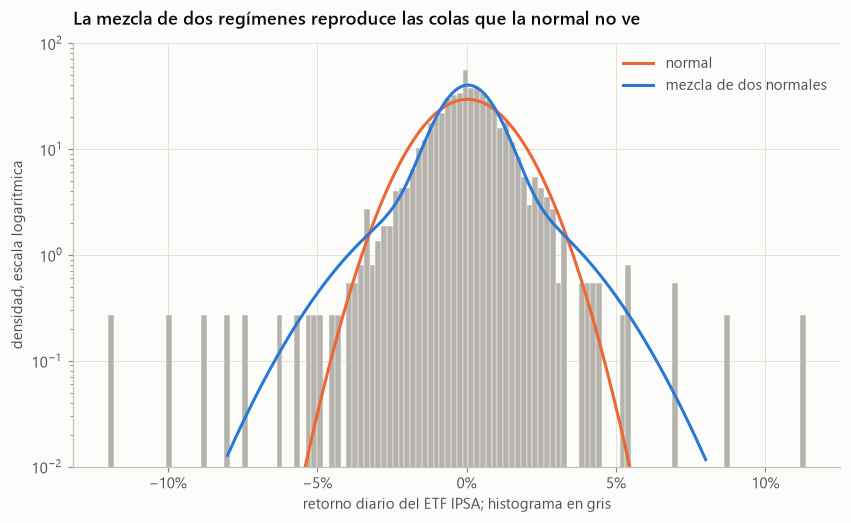

,muestra,normal,mezcla de dos normales
media,0.0003,0.0003,0.0003
desviación estándar,0.0136,0.0136,0.0136
asimetría,-0.3897,0.0000,-0.0843
curtosis,14.2867,3.0000,6.6465
cuantil 1%,-0.0342,-0.0313,-0.0409


In [5]:
from sklearn.mixture import GaussianMixture

x = r_ipsa.to_numpy()
mezcla = GaussianMixture(2, random_state=0).fit(x.reshape(-1, 1))
pesos, medias = mezcla.weights_, mezcla.means_.ravel()
desvios = np.sqrt(mezcla.covariances_.ravel())

media = pesos @ medias
centradas = medias - media
varianza = pesos @ (desvios**2 + centradas**2)
asimetria = pesos @ (centradas**3 + 3 * centradas * desvios**2) / varianza**1.5
curtosis = pesos @ (centradas**4 + 6 * centradas**2 * desvios**2 + 3 * desvios**4) / varianza**2

def cdf_mezcla(v):
    return float(pesos @ stats.norm.cdf(v, medias, desvios))

cuantil_mezcla = optimize.brentq(lambda v: cdf_mezcla(v) - 0.01, -0.2, 0.0)
regimenes = pd.DataFrame({"peso": pesos, "media diaria": medias, "volatilidad diaria": desvios}, index=["régimen 1", "régimen 2"])
comparacion = pd.DataFrame({
    "muestra": [x.mean(), x.std(), stats.skew(x), stats.kurtosis(x, fisher=False), np.quantile(x, 0.01)],
    "normal": [x.mean(), x.std(), 0.0, 3.0, stats.norm.ppf(0.01, x.mean(), x.std())],
    "mezcla de dos normales": [media, np.sqrt(varianza), asimetria, curtosis, cuantil_mezcla],
}, index=["media", "desviación estándar", "asimetría", "curtosis", "cuantil 1%"])
print(regimenes.to_string())

malla = np.linspace(-0.08, 0.08, 400)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(x, bins=120, density=True, color=NEUTRO, edgecolor="white", linewidth=0.3)
ax.semilogy(malla, stats.norm.pdf(malla, x.mean(), x.std()), color=COLORES[1], linewidth=2, label="normal")
ax.semilogy(malla, [pesos @ stats.norm.pdf(v, medias, desvios) for v in malla], color=COLORES[0], linewidth=2,
            label="mezcla de dos normales")
ax.set_ylim(1e-2, 100)
ax.legend(loc="upper right")
eje_porcentaje(ax, "x")
ax.set_xlabel("retorno diario del ETF IPSA; histograma en gris")
ax.set_ylabel("densidad, escala logarítmica")
ax.set_title("La mezcla de dos regímenes reproduce las colas que la normal no ve")
plt.show()
comparacion

**Lectura.**

- **La mezcla encuentra dos regímenes.** Uno tranquilo, 76% de los días, con volatilidad diaria de 0,84%, y otro agitado, 24% de los días, con 2,35%, casi el triple.
- **Explica parte de las colas.** Su curtosis es 6,6, más del doble que la normal, aunque menor que el 14,3 de la muestra, que incluye unos pocos días extremos como los de marzo de 2020. La normal subestima el cuantil 1%: −3,1% frente a −3,4% en la muestra.
- **En el gráfico, la normal cae a cero mucho antes que los datos; la mezcla sigue las colas.** Es la intuición de los modelos de volatilidad del libro 4: la varianza cambia en el tiempo, y mezclar días de varianza distinta produce colas gruesas.

### Ejercicios resueltos

**Ejercicio 2.1. Momentos de una distribución discreta de resultados** *(banco de ejercicios de frm-prep)*

Una distribución tiene media 8% y desviación de 20%: calcula su coeficiente de variación. Luego, una mesa tiene este resultado diario en millones: −10 con probabilidad 2%, −2 con 18%, 1 con 60% y 3 con 20%. Calcula su media, desviación, asimetría, curtosis y el VaR al 95%.

In [6]:
print(f"Coeficiente de variación: 20% / 8% = {0.20 / 0.08:.2f}")
valores = np.array([-10.0, -2.0, 1.0, 3.0])
prob = np.array([0.02, 0.18, 0.60, 0.20])
m = prob @ valores
d = np.sqrt(prob @ (valores - m) ** 2)
asim = prob @ (valores - m) ** 3 / d**3
curt = prob @ (valores - m) ** 4 / d**4
acumulada = np.cumsum(prob)
var95 = -valores[np.searchsorted(acumulada, 0.05)]
print(f"Media {m:.2f}, desviación {d:.2f}, asimetría {asim:.2f}, curtosis {curt:.2f}")
print(f"Respuesta: el 5% peor empieza en el resultado -2, así que el VaR al 95% es {var95:.0f} millones."
      " La asimetría negativa viene del evento raro de -10.")

Coeficiente de variación: 20% / 8% = 2.50
Media 0.64, desviación 2.17, asimetría -2.42, curtosis 12.23
Respuesta: el 5% peor empieza en el resultado -2, así que el VaR al 95% es 2 millones. La asimetría negativa viene del evento raro de -10.


**Ejercicio 2.2. Transformación lineal y suma de variables** *(ejercicio propio)*

Una posición en dólares rinde X millones de USD con media 2 y desviación 5. Se convierte a pesos con un dólar fijo de 950 y se le suma un ingreso fijo de 100 millones de pesos. ¿Cuál es la media y la desviación en pesos? Si además se suma otra posición Y con media 1 y desviación 4 millones de USD y correlación −0,3 con X, ¿cuál es la desviación de X + Y en dólares?

In [7]:
print(f"Media en pesos: 950 × 2 + 100 = {950 * 2 + 100:,.0f} millones; desviación: 950 × 5 = {950 * 5:,.0f} millones")
desv_suma = np.sqrt(5**2 + 4**2 + 2 * -0.3 * 5 * 4)
print(f"Respuesta: la desviación de X + Y es raíz(25 + 16 - 12) = {desv_suma:.2f} millones de USD, menos que 5 + 4 por la correlación negativa.")

Media en pesos: 950 × 2 + 100 = 2,000 millones; desviación: 950 × 5 = 4,750 millones
Respuesta: la desviación de X + Y es raíz(25 + 16 - 12) = 5.39 millones de USD, menos que 5 + 4 por la correlación negativa.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Para una variable que toma 10 (p=0.3), 20 (p=0.5), 30 (p=0.2) con media 19, la varianza es:

- **A.** 19
- **B.** 361
- **C.** 49
- **D.** 7

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** $E[X^2] = 100(0.3)+400(0.5)+900(0.2) = 410$. $\text{Var} = E[X^2] - (E[X])^2 = 410 - 19^2 = 410 - 361 = 49$.

</details>

**Pregunta 2** *(banco de frm-prep, cálculo, dificultad intermedia)*

Una distribución de retornos tiene una curtosis de 5. Su exceso de curtosis (respecto de la normal) es:

- **A.** 8
- **B.** 5
- **C.** 3
- **D.** 2

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Exceso de curtosis $= \text{curtosis} - 3 = 5 - 3 = 2$. Un exceso de curtosis positivo (leptocúrtica) indica colas más gruesas que la normal.

</details>

### Trampas frecuentes

- Sumar una constante cambia la media, pero no la varianza; multiplicar escala la desviación por el valor absoluto.
- Curtosis 5 es exceso de curtosis 2. Revisa cuál de las dos pide la pregunta.
- El VaR es un cuantil de la distribución de pérdidas, no un múltiplo de la desviación, salvo que se suponga normalidad.

## QA-3. Variables aleatorias univariadas comunes

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

| Distribución | Uso en riesgo | Momentos clave |
|---|---|---|
| Bernoulli y binomial | Incumplir o no; excepciones del VaR | $np$, $np(1-p)$ |
| Poisson | Conteo de eventos raros, como pérdidas operacionales | media = varianza = λ |
| Normal | Retornos en modelos simples | asimetría 0, curtosis 3 |
| Lognormal | Precios, que no pueden ser negativos | $E[X] = e^{\mu + \sigma^2/2}$ |
| t de Student | Retornos con colas pesadas | curtosis $3 + 6/(\nu - 4)$ para ν > 4 |
| Chi-cuadrado | Suma de normales al cuadrado; varianzas muestrales | media ν |
| F | Cociente de chi-cuadrados; pruebas de regresión | |
| Exponencial | Tiempo hasta un evento; intensidad de incumplimiento | media 1/λ |
| Beta | Tasas de recuperación entre 0 y 1 | |

La suma de normales independientes es normal. La binomial se aproxima con la Poisson cuando n es grande y p pequeño, y con la normal cuando np(1 − p) es grande.

### Análisis avanzado: normal, t de Student y el conteo de excepciones

Se ajustan una normal y una t de Student a los retornos diarios del ETF IPSA y se comparan sus cuantiles extremos con los de la muestra. Luego se calcula la distribución del número de excepciones de un VaR al 99% correcto en 250 días.

In [8]:
gl, loc, escala = riesgo.ajustar_t(r_ipsa)
media_r, desv_r = r_ipsa.mean(), r_ipsa.std()
filas = {}
for nivel in (0.99, 0.995, 0.999):
    filas[f"VaR {nivel:.1%}"] = {"muestra": riesgo.var_historico(r_ipsa, nivel), "normal": riesgo.var_normal(media_r, desv_r, nivel),
                                "t de Student": riesgo.var_t(gl, loc, escala, nivel)}
print(f"t de Student ajustada: {gl:.2f} grados de libertad, escala {escala:.4f}")
print(pd.DataFrame(filas).T.map("{:.2%}".format).to_string())

excepciones = np.arange(0, 11)
tabla_excepciones = pd.DataFrame({
    "binomial": stats.binom.pmf(excepciones, 250, 0.01),
    "Poisson": stats.poisson.pmf(excepciones, 2.5),
    "binomial, P(X ≥ k)": stats.binom.sf(excepciones - 1, 250, 0.01),
}, index=pd.Index(excepciones, name="excepciones"))
tabla_excepciones["zona de Basilea"] = [riesgo.semaforo_basilea(int(k)) for k in excepciones]
tabla_excepciones

t de Student ajustada: 3.40 grados de libertad, escala 0.0088
          muestra normal t de Student
VaR 99.0%   3.42%  3.13%        3.59%
VaR 99.5%   4.72%  3.47%        4.53%
VaR 99.9%   8.89%  4.17%        7.52%


,binomial,Poisson,"binomial, P(X ≥ k)",zona de Basilea
excepciones,,,,
0,0.0811,0.0821,1.0000,verde
1,0.2047,0.2052,0.9189,verde
2,0.2574,0.2565,0.7142,verde
3,0.2149,0.2138,0.4568,verde
4,0.1341,0.1336,0.2419,verde
5,0.0666,0.0668,0.1078,amarilla
6,0.0275,0.0278,0.0412,amarilla
7,0.0097,0.0099,0.0137,amarilla
8,0.0030,0.0031,0.0040,amarilla


**Lectura.**

- **La t ajustada tiene 3,4 grados de libertad:** colas muy pesadas.
- **Cuanto más lejos en la cola, peor la normal.** Al 99%, las tres medidas se parecen: 3,1% la normal, 3,4% la muestra y 3,6% la t. Al 99,9%, la normal da 4,2% y la muestra 8,9%, más del doble; la t, con 7,5%, queda mucho más cerca.
- **Un modelo correcto también cae en zona amarilla.** Con un VaR al 99% bien calibrado, cinco o más excepciones en 250 días ocurren el 10,8% de las veces: un banco con un buen modelo termina en zona amarilla uno de cada diez años. La Poisson con media 2,5 aproxima muy bien a la binomial.

### Ejercicios resueltos

**Ejercicio 3.1. Binomial** *(banco de ejercicios de frm-prep)*

Una binomial tiene n = 20 ensayos y probabilidad de éxito de 0,10. Calcula su media, varianza y desviación, y la probabilidad de tres éxitos o más.

In [9]:
n, p = 20, 0.10
print(f"Media {n * p:.1f}, varianza {n * p * (1 - p):.2f}, desviación {np.sqrt(n * p * (1 - p)):.2f}")
print(f"Respuesta: P(X ≥ 3) = 1 - P(X ≤ 2) = {stats.binom.sf(2, n, p):.1%}")

Media 2.0, varianza 1.80, desviación 1.34
Respuesta: P(X ≥ 3) = 1 - P(X ≤ 2) = 32.3%


**Ejercicio 3.2. Probabilidad de un precio lognormal** *(ejercicio propio)*

El dólar vale hoy su último valor observado y su volatilidad anual de los últimos dos años es la calculada abajo. Suponiendo un precio lognormal sin tendencia (μ = 0), ¿cuál es la probabilidad de que en un año supere en 10% el valor actual? ¿Y el valor esperado del dólar en un año?

In [10]:
spot = float(dolar.iloc[-1])
vol = float(np.log(dolar).diff().loc[dolar.index[-1] - pd.DateOffset(years=2):].std() * np.sqrt(252))
umbral = 1.10 * spot
# ln S_T ~ N(ln S_0 + (μ - σ²/2)T, σ²T)
z_ = (np.log(umbral / spot) + vol**2 / 2) / vol
print(f"Spot {spot:,.2f}, volatilidad {vol:.1%}")
print(f"Respuesta: P(S_T > {umbral:,.0f}) = N(-{z_:.3f}) = {stats.norm.sf(z_):.1%}; E[S_T] = S_0·e^(μT) = {spot:,.2f}."
      " La mediana, S_0·e^(-σ²/2), queda algo más abajo.")

Spot 959.39, volatilidad 10.7%
Respuesta: P(S_T > 1,055) = N(-0.945) = 17.2%; E[S_T] = S_0·e^(μT) = 959.39. La mediana, S_0·e^(-σ²/2), queda algo más abajo.


**Ejercicio 3.3. Poisson para eventos operacionales** *(ejercicio propio)*

Un banco espera 3 fraudes grandes al año. ¿Cuál es la probabilidad de tener 6 o más en un año? ¿Y de pasar un año sin ninguno?

In [11]:
print(f"P(N ≥ 6) = {stats.poisson.sf(5, 3):.2%}")
print(f"Respuesta: P(N = 0) = e^-3 = {stats.poisson.pmf(0, 3):.2%}. Con media y varianza iguales a 3, seis eventos no son tan raros.")

P(N ≥ 6) = 8.39%
Respuesta: P(N = 0) = e^-3 = 4.98%. Con media y varianza iguales a 3, seis eventos no son tan raros.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Una variable $X = e^{Y}$ donde $Y \sim N(\mu = 0, \sigma = 0.2)$. El valor esperado $E[X]$ es más cercano a:

- **A.** 1.0202
- **B.** 0.9802
- **C.** 1.0000
- **D.** 1.2214

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Para una lognormal, $E[X] = e^{\mu + \sigma^2/2} = e^{0 + 0.2^2/2} = e^{0.02} \approx 1.0202$. La media supera $e^{\mu}=1$ por la desigualdad de Jensen.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

La distribución t de Student difiere de la normal estándar en que:

- **A.** no tiene media definida.
- **B.** tiene colas más delgadas que la normal.
- **C.** tiene colas más gruesas, controladas por sus grados de libertad, convergiendo a la normal cuando estos crecen.
- **D.** siempre es sesgada.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** La distribución t es simétrica y acampanada pero con colas más gruesas que la normal, especialmente con pocos grados de libertad. Se usa para inferencia con muestras pequeñas o varianza desconocida, y se aproxima a la normal cuando aumentan los grados de libertad.

</details>

### Trampas frecuentes

- La media de una lognormal es e^(μ + σ²/2), no e^μ: la desigualdad de Jensen la empuja hacia arriba.
- La t de Student converge a la normal cuando crecen los grados de libertad; con pocos, sus colas son mucho más gruesas.
- En la Poisson, la media y la varianza son iguales. Si los datos tienen más varianza que media, la Poisson no sirve.

## QA-4. Variables aleatorias multivariadas

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Distribuciones conjunta, marginal y condicional.** $f(y|x) = f(x, y)/f_X(x)$. Independencia significa que la conjunta es el producto de las marginales.
- **Covarianza y correlación.** $\rho = \text{Cov}(X, Y)/(\sigma_X\sigma_Y)$ mide solo dependencia lineal. Correlación cero no implica independencia, salvo en la normal multivariada.
- **Normal bivariada.** $E[Y|X = x] = \mu_Y + \rho\frac{\sigma_Y}{\sigma_X}(x - \mu_X)$ y $V[Y|X] = \sigma_Y^2(1 - \rho^2)$.
- **Varianza de una cartera.** $w'\Sigma w$; con n activos de igual varianza y correlación, tiende a $\rho\sigma^2$ cuando n crece.
- **Cópulas.** Separan las marginales de la dependencia. La cópula gaussiana no tiene dependencia en las colas: en el límite, los extremos llegan solos. La cópula t sí la tiene, y por eso las caídas conjuntas son más probables.

### Análisis avanzado: dependencia en las colas y cópulas

Las caídas del IPSA coinciden con subidas del dólar. Para medir si los extremos llegan juntos, se calcula la probabilidad empírica de que el dólar tenga uno de sus peores días (para un inversionista en pesos, una subida) dado que el IPSA tiene uno de los suyos. Se compara con lo que predicen una cópula gaussiana y una cópula t con 4 grados de libertad, ambas calibradas con la misma tau de Kendall.

Tau de Kendall 0.160; correlación de la cópula 0.249


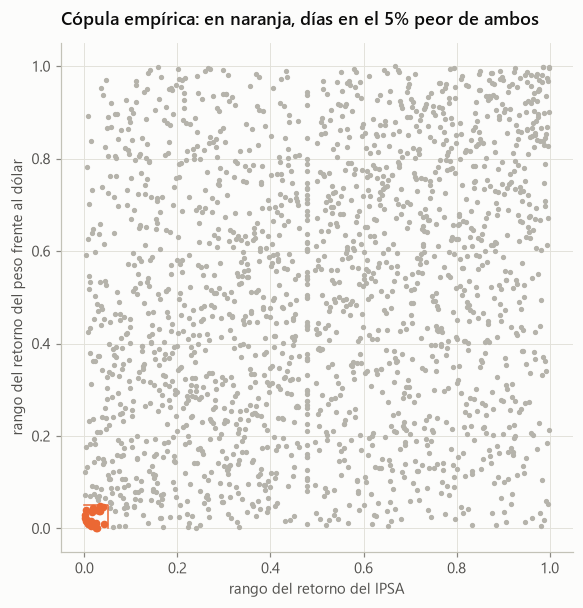

,datos,cópula gaussiana,"cópula t, ν = 4",independencia,días en la cola del IPSA
10.0%,0.2513,0.1925,0.2596,0.1000,191.0000
5.0%,0.2083,0.1222,0.2168,0.0500,95.0000
2.5%,0.1667,0.0788,0.1990,0.0250,48.0000
1.0%,0.0500,0.0410,0.1695,0.0100,19.0000


In [12]:
x_cola, y_cola = diario["ipsa"].to_numpy(), -diario["dolar"].to_numpy()
tau = stats.kendalltau(x_cola, y_cola)[0]
rho_copula = fa.rho_desde_tau(tau)
rng = np.random.default_rng(3)
n_sim = 200_000
cov_copula = [[1, rho_copula], [rho_copula, 1]]
gauss = rng.multivariate_normal([0, 0], cov_copula, n_sim)
t_copula = rng.multivariate_normal([0, 0], cov_copula, n_sim) / np.sqrt(rng.chisquare(4, n_sim) / 4)[:, None]

filas = {}
for q in (0.10, 0.05, 0.025, 0.01):
    filas[f"{q:.1%}"] = {"datos": fa.dependencia_cola_inferior(x_cola, y_cola, q),
                         "cópula gaussiana": fa.dependencia_cola_inferior(gauss[:, 0], gauss[:, 1], q),
                         "cópula t, ν = 4": fa.dependencia_cola_inferior(t_copula[:, 0], t_copula[:, 1], q),
                         "independencia": q, "días en la cola del IPSA": int(round(q * len(x_cola)))}
print(f"Tau de Kendall {tau:.3f}; correlación de la cópula {rho_copula:.3f}")

u = stats.rankdata(x_cola) / (len(x_cola) + 1)
v = stats.rankdata(y_cola) / (len(y_cola) + 1)
en_cola = (u < 0.05) & (v < 0.05)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(u[~en_cola], v[~en_cola], s=6, color=NEUTRO)
ax.scatter(u[en_cola], v[en_cola], s=16, color=COLORES[1])
ax.plot([0, 0.05, 0.05], [0.05, 0.05, 0], color=COLORES[1], linewidth=1)
ax.set_xlabel("rango del retorno del IPSA")
ax.set_ylabel("rango del retorno del peso frente al dólar")
ax.set_title("Cópula empírica: en naranja, días en el 5% peor de ambos")
plt.show()
pd.DataFrame(filas).T

**Lectura.**

- **Las caídas del IPSA y del peso llegan juntas más de lo que dice la correlación.** En el 5% de los peores días del IPSA, el peso tiene uno de sus peores días el 21% de las veces, cuatro veces lo esperable bajo independencia.
- **La cópula gaussiana subestima esa coincidencia y la t la reproduce.** Al 5%, la gaussiana predice 12% y la t 22%; al 2,5%, los datos muestran 17%, la gaussiana 8% y la t 20%. Al 1% solo hay 19 días en la cola, demasiado pocos para estimar con precisión.
- **Para simular pérdidas conjuntas, la cópula importa tanto como la correlación.** Ambas cópulas tienen la misma tau de Kendall, y aun así difieren por un factor de dos en las colas.

### Ejercicios resueltos

**Ejercicio 4.1. Correlación desde la covarianza** *(banco de ejercicios de frm-prep)*

Dos activos tienen una covarianza de 0,009 y desviaciones de 10% y 15%. ¿Cuál es su correlación?

In [13]:
print(f"Respuesta: ρ = 0,009 / (0,10 × 0,15) = {0.009 / (0.10 * 0.15):.2f}")

Respuesta: ρ = 0,009 / (0,10 × 0,15) = 0.60


**Ejercicio 4.2. Esperanza condicional en la normal bivariada** *(ejercicio propio)*

Suponiendo que los retornos diarios del IPSA y del dólar son normales bivariados con los parámetros de la muestra, ¿qué retorno se espera del IPSA un día en que el dólar sube 2%? ¿Cuánto se reduce la desviación del IPSA al conocer el dólar?

In [14]:
mu_x, mu_y = diario["dolar"].mean(), diario["ipsa"].mean()
s_x, s_y = diario["dolar"].std(), diario["ipsa"].std()
rho_xy = diario.corr().loc["dolar", "ipsa"]
esperado = mu_y + rho_xy * s_y / s_x * (0.02 - mu_x)
desv_condicional = s_y * np.sqrt(1 - rho_xy**2)
print(f"ρ = {rho_xy:.3f}; E[IPSA | dólar +2%] = {esperado:.2%}")
print(f"Respuesta: la desviación del IPSA baja de {s_y:.2%} a {desv_condicional:.2%}: conocer el dólar ayuda poco, porque ρ² = {rho_xy**2:.1%}.")

ρ = -0.262; E[IPSA | dólar +2%] = -0.85%
Respuesta: la desviación del IPSA baja de 1.36% a 1.31%: conocer el dólar ayuda poco, porque ρ² = 6.9%.


**Ejercicio 4.3. Correlación cero sin independencia** *(ejercicio propio)*

Sea X normal estándar e Y = X². Muestra que la correlación es cero aunque Y depende por completo de X.

In [15]:
rng = np.random.default_rng(0)
x_ = rng.standard_normal(1_000_000)
y_ = x_**2
print(f"Correlación muestral: {np.corrcoef(x_, y_)[0, 1]:.4f}")
print(f"E[Y | |X| > 2] = {y_[np.abs(x_) > 2].mean():.2f} frente a E[Y] = {y_.mean():.2f}")
print("Respuesta: Cov(X, X²) = E[X³] = 0 por simetría. La correlación solo capta relaciones lineales.")

Correlación muestral: 0.0005
E[Y | |X| > 2] = 5.76 frente a E[Y] = 1.00
Respuesta: Cov(X, X²) = E[X³] = 0 por simetría. La correlación solo capta relaciones lineales.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

En una regresión de Y sobre X, la pendiente es 0.8. La desviación estándar de X es 10% y la de Y es 16%. La correlación entre X e Y es:

- **A.** 0.80
- **B.** 1.28
- **C.** 0.50
- **D.** 0.128

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** $\rho = \hat{\beta}\,\dfrac{\sigma_X}{\sigma_Y} = 0.8 \times \dfrac{0.10}{0.16} = 0.50$.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Un gestor de riesgos modela incumplimientos conjuntos usando cópula gaussiana vs. t con la misma correlación. La cópula t producirá ¿qué resultado?

- **A.** Menor probabilidad de incumplimiento conjunto porque la distribución t tiene colas más delgadas que la normal
- **B.** Menores probabilidades de incumplimiento individual porque la cópula t desplaza masa hacia el centro
- **C.** Mayor probabilidad de eventos extremos simultáneos debido a mayor dependencia de cola en la cópula t
- **D.** La misma probabilidad de incumplimiento conjunto ya que ambas comparten el mismo parámetro de correlación

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** La cópula gaussiana tiene dependencia de cola cero. La cópula t exhibe dependencia de cola positiva: los eventos extremos en una variable aumentan la probabilidad de eventos extremos en la otra. Esta fue una lección clave de la crisis financiera 2007-2009, donde la cópula gaussiana fue ampliamente culpada por subestimar los incumplimientos conjuntos.

</details>

### Trampas frecuentes

- Correlación cero implica independencia solo si las variables son normales conjuntas.
- La cópula gaussiana subestima las caídas conjuntas: su dependencia en la cola tiende a cero.
- La varianza de una suma lleva el término 2·Cov; con correlación negativa, la suma es menos riesgosa que las partes.

## QA-5. Momentos muestrales

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Propiedades de un estimador.** Insesgado si $E[\hat\theta] = \theta$; consistente si converge al valor verdadero cuando n crece; eficiente si tiene la menor varianza entre los insesgados. MCO es BLUE bajo Gauss-Markov.
- **Media muestral.** Su error estándar es $\sigma/\sqrt{n}$ y, por el teorema central del límite, es aproximadamente normal. Con autocorrelación positiva, el error real es mayor.
- **Varianza muestral.** Dividir por n − 1 la hace insesgada; dividir por n la sesga hacia abajo, pero da un error cuadrático medio menor.
- **Momentos altos.** La asimetría y la curtosis muestrales tienen errores estándar aproximados de $\sqrt{6/n}$ y $\sqrt{24/n}$ con datos normales, y mucho mayores con colas pesadas.
- **Mediana y cuantiles.** Son robustos a los extremos; el cuantil muestral es la base del VaR histórico.

### Análisis avanzado: cuán inciertas son la curtosis y el Sharpe estimados

Primero se simulan 5.000 muestras de un año de retornos diarios, 250 días, de una t de Student con 6 grados de libertad, cuya curtosis verdadera es 6. Luego se calcula el error estándar del Sharpe de cada acción del IPSA con la fórmula de Mertens, que corrige por asimetría y curtosis.

In [16]:
rng = np.random.default_rng(5)
nu, n_dias, repeticiones = 6, 250, 5_000
muestras = stats.t.rvs(nu, size=(repeticiones, n_dias), random_state=rng) * 0.01 / np.sqrt(nu / (nu - 2))
estimadores = {
    "media": (0.0, muestras.mean(axis=1)),
    "varianza, n - 1": (0.01**2, muestras.var(axis=1, ddof=1)),
    "asimetría": (0.0, stats.skew(muestras, axis=1)),
    "curtosis": (3 + 6 / (nu - 4), stats.kurtosis(muestras, axis=1, fisher=False)),
}
filas = {}
for nombre, (verdadero, estimaciones) in estimadores.items():
    filas[nombre] = {"valor verdadero": verdadero, "promedio de las estimaciones": estimaciones.mean(),
                     "percentil 5%": np.quantile(estimaciones, 0.05), "percentil 95%": np.quantile(estimaciones, 0.95)}
print(pd.DataFrame(filas).T.to_string(float_format=lambda v: f"{v:.6f}" if abs(v) < 0.01 else f"{v:.3f}"))

pequenas = muestras[:, :10]
print(f"\nCon n = 10, la varianza dividida por n promedia {pequenas.var(axis=1, ddof=0).mean() / 0.01**2:.3f} veces la verdadera;"
      f" dividida por n - 1, {pequenas.var(axis=1, ddof=1).mean() / 0.01**2:.3f}.")

rf_diario = 0.049 / 252
filas = {}
for accion in acciones + ["ETF IPSA"]:
    exceso = retornos[accion] - rf_diario
    sr = exceso.mean() / exceso.std()
    error = fa.error_estandar_sharpe(sr, len(exceso), stats.skew(exceso), stats.kurtosis(exceso, fisher=False))
    filas[accion] = {"Sharpe anual": sr * np.sqrt(252), "error estándar anual": error * np.sqrt(252),
                     "límite inferior 95%": (sr - 1.96 * error) * np.sqrt(252), "límite superior 95%": (sr + 1.96 * error) * np.sqrt(252)}
tabla_sharpe = pd.DataFrame(filas).T
tabla_sharpe["distinto de cero al 5%"] = tabla_sharpe["límite inferior 95%"] > 0
tabla_sharpe

                 valor verdadero  promedio de las estimaciones  percentil 5%  percentil 95%
media                   0.000000                     -0.000009     -0.001047       0.001034
varianza, n - 1         0.000100                      0.000100      0.000080       0.000125
asimetría               0.000000                     -0.003830        -0.696          0.695
curtosis                   6.000                         5.176         3.290          8.982

Con n = 10, la varianza dividida por n promedia 0.894 veces la verdadera; dividida por n - 1, 0.993.


,Sharpe anual,error estándar anual,límite inferior 95%,límite superior 95%,distinto de cero al 5%
BCI,0.4461,0.3637,-0.2669,1.1590,False
Santander,0.3409,0.3651,-0.3746,1.0564,False
Banco de Chile,0.4796,0.3610,-0.2280,1.1871,False
Cencosud,0.3614,0.3632,-0.3504,1.0732,False
CMPC,-0.2155,0.3637,-0.9284,0.4974,False
Copec,-0.1132,0.3637,-0.8261,0.5997,False
Enel Chile,0.2476,0.3630,-0.4640,0.9592,False
Falabella,0.1265,0.3633,-0.5856,0.8386,False
SQM-B,0.4054,0.3631,-0.3062,1.1170,False
ETF IPSA,0.1192,0.3640,-0.5942,0.8326,False


**Lectura.**

- **La media y la varianza se estiman razonablemente con un año de datos; la curtosis, no.** Con una curtosis verdadera de 6, el promedio de las estimaciones es 5,2, sesgado hacia abajo, y el 90% de ellas cae entre 3,3 y 9,0.
- **El sesgo de la varianza es el teórico.** Con 10 observaciones, dividir por n da en promedio 0,89 veces la varianza verdadera, cerca del 0,9 que predice la teoría; dividir por n − 1 da 0,99.
- **Ningún Sharpe es distinto de cero.** Los Sharpe anuales van de −0,22 en CMPC a 0,48 en Banco de Chile, con un error estándar de 0,36 en todos los casos. Con siete años y medio de datos, ni el mejor se distingue de la suerte.

### Ejercicios resueltos

**Ejercicio 5.1. Intervalo de confianza para la media** *(banco de ejercicios de frm-prep)*

Una muestra de 100 observaciones tiene media 50 y desviación estándar 10. Construye el intervalo de confianza al 95% para la media. ¿Cuántas observaciones harían falta para que el margen fuera 1?

In [17]:
margen = 1.96 * 10 / np.sqrt(100)
print(f"IC 95% = 50 ± 1,96 × 10 / 10 = [{50 - margen:.2f}, {50 + margen:.2f}]")
print(f"Respuesta: para un margen de 1, n = (1,96 × 10 / 1)² = {np.ceil((1.96 * 10) ** 2):.0f} observaciones.")

IC 95% = 50 ± 1,96 × 10 / 10 = [48.04, 51.96]
Respuesta: para un margen de 1, n = (1,96 × 10 / 1)² = 385 observaciones.


**Ejercicio 5.2. Media aritmética frente a geométrica** *(ejercicio propio)*

Calcula los retornos anuales del ETF IPSA por año calendario, su media aritmética y geométrica, y comprueba la aproximación $G \approx A - \sigma^2/2$.

In [18]:
serie_ipsa = precios["ETF IPSA"]
cierres = pd.concat([serie_ipsa.iloc[:1], serie_ipsa.resample("YE").last()])
anuales = cierres.pct_change().dropna().loc[:"2025"]  # 2019 desde el primer día disponible; 2026 está incompleto
aritmetica, geometrica = anuales.mean(), (1 + anuales).prod() ** (1 / len(anuales)) - 1
print(anuales.map("{:.1%}".format).to_string())
print(f"Aritmética {aritmetica:.2%}; geométrica {geometrica:.2%}; aproximación A - σ²/2 = {aritmetica - anuales.var(ddof=0) / 2:.2%}")
print("Respuesta: la geométrica, que es lo que realmente creció la inversión, queda bajo la aritmética por la volatilidad.")

fecha
2019-12-31     -8.7%
2020-12-31    -10.0%
2021-12-31     -4.9%
2022-12-31     11.1%
2023-12-31      9.7%
2024-12-31      2.9%
2025-12-31     49.5%
Aritmética 7.07%; geométrica 5.60%; aproximación A - σ²/2 = 5.27%
Respuesta: la geométrica, que es lo que realmente creció la inversión, queda bajo la aritmética por la volatilidad.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Una inversión rinde +10% en el año 1 y -10% en el año 2. Su retorno anual medio geométrico es más cercano a:

- **A.** -0.50%
- **B.** -10.00%
- **C.** 0.50%
- **D.** 0.00%

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Media geométrica $= \sqrt{(1.10)(0.90)} - 1 = \sqrt{0.99} - 1 \approx -0.50\%$. Está por debajo de la media aritmética de 0% por el efecto de la volatilidad (volatility drag).

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

La asimetría negativa en los retornos accionarios es la más preocupante para los gestores de riesgo porque:

- **A.** Hay una mayor probabilidad de retornos negativos extremos de la que implicaría una distribución simétrica
- **B.** Los retornos están acotados inferiormente por cero
- **C.** Significa que el retorno medio es negativo
- **D.** La volatilidad está subestimada

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** La asimetría negativa significa que la cola izquierda es más pesada: pérdidas más grandes y frecuentes de lo que predice una distribución simétrica. Los modelos de VaR que suponen normalidad subestimarán el riesgo a la baja de activos con asimetría negativa.

</details>

### Trampas frecuentes

- Insesgado no significa preciso: un estimador puede acertar en promedio y variar muchísimo entre muestras.
- Dividir por n − 1 corrige el sesgo de la varianza, no el de la desviación estándar.
- La media geométrica siempre es menor o igual que la aritmética; la diferencia crece con la volatilidad.

## QA-6. Pruebas de hipótesis

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Estructura.** Hipótesis nula y alternativa, estadístico de prueba, distribución bajo la nula, nivel de significancia α y regla de decisión. El valor p es la probabilidad de un resultado tan extremo como el observado si la nula es cierta.
- **Errores.** Tipo I: rechazar una nula verdadera, con probabilidad α. Tipo II: no rechazar una nula falsa, con probabilidad β. La potencia es 1 − β y crece con n y con el tamaño del efecto.
- **Pruebas comunes.** Media con t de Student, $t = (\bar x - \mu_0)/(s/\sqrt n)$; diferencia de medias; varianza con chi-cuadrado; igualdad de varianzas con F.
- **Pruebas múltiples.** Si se prueban m hipótesis al 5%, la probabilidad de al menos un falso positivo es $1 - 0,95^m$. Bonferroni usa α/m para controlarla; Holm y el control de la tasa de falsos descubrimientos son menos conservadores.

### Análisis avanzado: minería de datos con 200 estrategias al azar

Se crean 200 estrategias que cada día se ponen largas o cortas en el ETF IPSA lanzando una moneda. Ninguna tiene habilidad. Aun así, algunas parecerán significativas si se prueba cada una por separado. Luego se calcula cuántos años de datos hacen falta para detectar un Sharpe verdadero con potencia de 80%.

Estrategias significativas al 5%: 6 de 200 (se esperan 10 por azar)
Con Bonferroni (α = 0,05/200): 0
La mejor tiene t = 2.40 y un Sharpe anual de 0.87, sin ninguna habilidad.


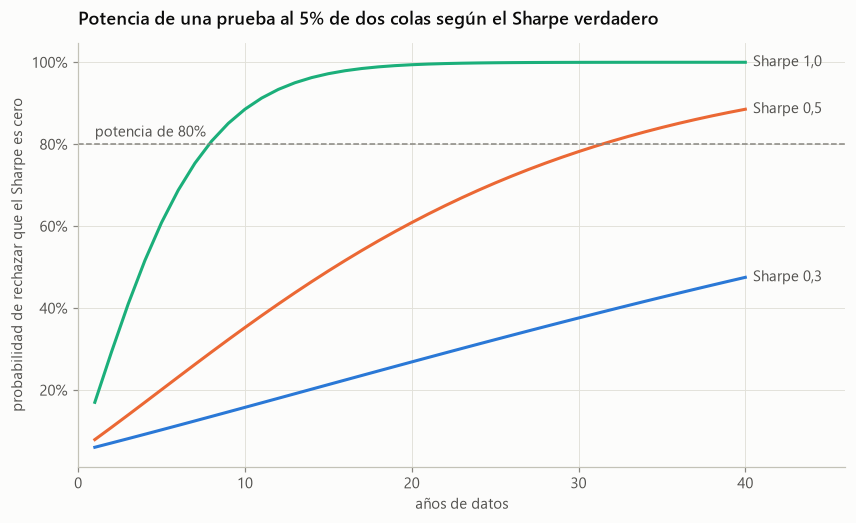

,años para 80% de potencia
Sharpe 0.3,87.2000
Sharpe 0.5,31.4000
Sharpe 1.0,7.8000


In [19]:
rng = np.random.default_rng(6)
senales = rng.choice([-1.0, 1.0], size=(200, len(r_ipsa)))
resultados = senales * r_ipsa.to_numpy()
t_est = resultados.mean(axis=1) / (resultados.std(axis=1, ddof=1) / np.sqrt(resultados.shape[1]))
p_valores = 2 * stats.norm.sf(np.abs(t_est))
sharpe_anual = resultados.mean(axis=1) / resultados.std(axis=1) * np.sqrt(252)
print(f"Estrategias significativas al 5%: {(p_valores < 0.05).sum()} de 200 (se esperan 10 por azar)")
print(f"Con Bonferroni (α = 0,05/200): {(p_valores < 0.05 / 200).sum()}")
print(f"La mejor tiene t = {t_est.max():.2f} y un Sharpe anual de {sharpe_anual.max():.2f}, sin ninguna habilidad.")

anios = np.arange(1, 41)
fig, ax = plt.subplots(figsize=(9, 5))
for color, sr in zip(COLORES, (0.3, 0.5, 1.0)):
    potencia = [fa.potencia_prueba_media(sr, 1.0, int(a)) for a in anios]
    ax.plot(anios, potencia, color=color, linewidth=2)
    ax.annotate(f"Sharpe {sr:.1f}".replace(".", ","), (anios[-1], potencia[-1]), xytext=(5, 0), textcoords="offset points",
                va="center", color=TINTA_SECUNDARIA)
ax.axhline(0.8, color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.annotate("potencia de 80%", (1, 0.8), xytext=(0, 5), textcoords="offset points", color=TINTA_SECUNDARIA)
eje_porcentaje(ax)
ax.set_xlim(0, 46)
ax.set_xlabel("años de datos")
ax.set_ylabel("probabilidad de rechazar que el Sharpe es cero")
ax.set_title("Potencia de una prueba al 5% de dos colas según el Sharpe verdadero")
plt.show()
pd.Series({f"Sharpe {sr}": ((stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) / sr) ** 2 for sr in (0.3, 0.5, 1.0)},
          name="años para 80% de potencia").round(1).to_frame()

**Lectura.**

- **El azar produce estrategias que parecen buenas.** Seis de las 200 estrategias al azar son significativas al 5%, y la mejor tiene un t de 2,4 y un Sharpe de 0,87 sin ninguna habilidad. Con la corrección de Bonferroni, ninguna sobrevive. Un backtest que prueba muchas variantes y reporta la mejor siempre encuentra algo.
- **Detectar habilidad real exige décadas.** Con potencia de 80%, un Sharpe de 0,5 requiere 31 años de datos; uno de 1,0, unos 8 años, y uno de 0,3, 87 años. Por eso el desempeño pasado de un gestor dice tan poco.

### Ejercicios resueltos

**Ejercicio 6.1. Prueba t de una media** *(banco de ejercicios de frm-prep)*

Una muestra de 64 observaciones tiene media 105 y desviación 20. Prueba H₀: μ = 100 al 5% con dos colas y calcula el valor p.

In [20]:
t_ = (105 - 100) / (20 / np.sqrt(64))
print(f"t = (105 - 100) / (20 / 8) = {t_:.2f}; valor p = {2 * stats.t.sf(t_, 63):.4f}")
print("Respuesta: t = 2,0 supera el valor crítico de 1,998 con 63 grados de libertad: se rechaza H₀ al 5%, por muy poco.")

t = (105 - 100) / (20 / 8) = 2.00; valor p = 0.0498
Respuesta: t = 2,0 supera el valor crítico de 1,998 con 63 grados de libertad: se rechaza H₀ al 5%, por muy poco.


**Ejercicio 6.2. El efecto lunes en el IPSA** *(ejercicio propio)*

¿Es distinto el retorno medio del ETF IPSA los lunes que el resto de los días? Usa la prueba de Welch, que no supone varianzas iguales.

In [21]:
lunes = r_ipsa[r_ipsa.index.dayofweek == 0]
otros = r_ipsa[r_ipsa.index.dayofweek != 0]
t_w, p_w = stats.ttest_ind(lunes, otros, equal_var=False)
print(f"Media lunes {lunes.mean():.3%} ({len(lunes)} días); resto {otros.mean():.3%} ({len(otros)} días)")
print(f"Respuesta: t de Welch = {t_w:.2f}, valor p = {p_w:.3f}. {'Se rechaza' if p_w < 0.05 else 'No se rechaza'} la igualdad al 5%.")

Media lunes -0.083% (380 días); resto 0.058% (1528 días)
Respuesta: t de Welch = -1.54, valor p = 0.125. No se rechaza la igualdad al 5%.


**Ejercicio 6.3. Pruebas múltiples** *(ejercicio propio)*

Un analista prueba 20 factores independientes al 5%. Si ninguno tiene poder predictivo, ¿cuál es la probabilidad de encontrar al menos uno significativo? ¿Qué nivel exige Bonferroni?

In [22]:
print(f"P(al menos un falso positivo) = 1 - 0,95^20 = {1 - 0.95**20:.1%}")
print(f"Respuesta: Bonferroni exige un valor p menor que 0,05 / 20 = {0.05 / 20:.4f} para cada factor.")

P(al menos un falso positivo) = 1 - 0,95^20 = 64.2%
Respuesta: Bonferroni exige un valor p menor que 0,05 / 20 = 0.0025 para cada factor.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Un analista de riesgos contrasta si el P&L medio diario de una mesa de trading es significativamente distinto de cero. Con 100 observaciones, media muestral = $15,000, desviación estándar muestral = $80,000. Usando un nivel de significancia del 5% (dos colas), ¿cuál es el estadístico t y cuál es la conclusión?

- **A.** t = 1.875; se rechaza H₀: el P&L medio es significativamente distinto de cero.
- **B.** t = 1.875; no se rechaza H₀: el P&L medio no es significativamente distinto de cero.
- **C.** t = 18.75; se rechaza H₀.
- **D.** t = 0.188; no se rechaza H₀.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** t = (x̄ – μ₀) / (s/√n) = (15,000 – 0) / (80,000/√100) = 15,000 / 8,000 = 1.875. Para una prueba de dos colas al 5% con gl ≈ 99, el valor crítico es aproximadamente ±1.984. Como |1.875| < 1.984, no se rechaza H₀. El P&L medio no es estadísticamente distinto de cero al 5%.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Un equipo de validación de modelos establece el nivel de significancia de la prueba retrospectiva en 1%. ¿Cuál es el principal compromiso?

- **A.** Establecer alpha=1% reduce la probabilidad de error tipo I pero aumenta la probabilidad de error tipo II en comparación con alpha=5%
- **B.** Establecer alpha=1% elimina los errores tipo II mientras aumenta los errores tipo I en comparación con alpha=5%
- **C.** Establecer alpha=1% reduce ambos tipos de errores simultáneamente
- **D.** Establecer alpha=1% aumenta la potencia estadística

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Reducir alpha disminuye el error tipo I (rechazar falsamente un buen modelo) pero aumenta el error tipo II (no detectar un modelo defectuoso). Ambos errores no pueden reducirse simultáneamente sin aumentar el tamaño de la muestra.

</details>

### Trampas frecuentes

- No rechazar H₀ no prueba que sea cierta: puede faltar potencia.
- Bajar α reduce el error tipo I pero aumenta el tipo II, salvo que aumente la muestra.
- El valor p no es la probabilidad de que H₀ sea cierta.
- Con muchas pruebas, algunas saldrán significativas por azar: hay que ajustar el nivel.

## QA-7. Regresión lineal

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Estimadores de MCO.** $\hat\beta = \text{Cov}(X, Y)/\text{Var}(X)$ y $\hat\alpha = \bar y - \hat\beta\bar x$. En forma matricial, $\hat\beta = (X'X)^{-1}X'y$.
- **Ajuste.** $R^2 = 1 - SSR/SST$; en la regresión simple es el cuadrado de la correlación.
- **Inferencia.** $SE(\hat\beta) = s/\sqrt{\sum(x_i - \bar x)^2}$ con $s^2 = SSR/(n - 2)$, y $t = (\hat\beta - \beta_0)/SE(\hat\beta)$ con n − 2 grados de libertad.
- **Supuestos.** Linealidad, media condicional cero del error, observaciones i.i.d., sin extremos grandes y, para eficiencia, homocedasticidad.
- **Variables dicotómicas.** Una dummy desplaza el intercepto; su interacción con X cambia la pendiente en un período o grupo.

### Análisis avanzado: beta de un banco en tiempos normales y de crisis

Se estima la beta de Banco de Chile respecto del ETF IPSA primero con álgebra matricial y luego con statsmodels, y se agrega una dummy para dos crisis: el estallido social (18 de octubre a 31 de diciembre de 2019) y el inicio de la pandemia (marzo a mayo de 2020).

In [23]:
y_banco, x_ipsa = retornos["Banco de Chile"], retornos["ETF IPSA"]
X = np.column_stack([np.ones(len(x_ipsa)), x_ipsa])
beta_mco = np.linalg.solve(X.T @ X, X.T @ y_banco)
residuos = y_banco - X @ beta_mco
s2 = residuos @ residuos / (len(y_banco) - 2)
errores = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))
modelo_simple = sm.OLS(y_banco, sm.add_constant(x_ipsa)).fit()
print(f"Álgebra matricial: α = {beta_mco[0]:.5f}, β = {beta_mco[1]:.4f}, SE(β) = {errores[1]:.4f}")
print(f"statsmodels:       α = {modelo_simple.params.iloc[0]:.5f}, β = {modelo_simple.params.iloc[1]:.4f}, SE(β) = {modelo_simple.bse.iloc[1]:.4f}, R² = {modelo_simple.rsquared:.3f}")

indice = y_banco.index
crisis = (((indice >= "2019-10-18") & (indice <= "2019-12-31")) | ((indice >= "2020-03-01") & (indice <= "2020-05-31"))).astype(float)
X_crisis = pd.DataFrame({"constante": 1.0, "IPSA": x_ipsa, "crisis": crisis, "IPSA × crisis": x_ipsa * crisis}, index=indice)
modelo_crisis = sm.OLS(y_banco, X_crisis).fit()
print(f"Días de crisis: {int(crisis.sum())}. Beta normal: {modelo_crisis.params['IPSA']:.3f};"
      f" beta en crisis: {modelo_crisis.params['IPSA'] + modelo_crisis.params['IPSA × crisis']:.3f}")
pd.DataFrame({"coeficiente": modelo_crisis.params, "error estándar": modelo_crisis.bse, "t": modelo_crisis.tvalues,
              "valor p": modelo_crisis.pvalues})

Álgebra matricial: α = 0.00047, β = 0.7909, SE(β) = 0.0222
statsmodels:       α = 0.00047, β = 0.7909, SE(β) = 0.0222, R² = 0.400
Días de crisis: 111. Beta normal: 0.715; beta en crisis: 0.996


,coeficiente,error estándar,t,valor p
constante,0.0006,0.0003,1.8022,0.0717
IPSA,0.7151,0.0257,27.7933,0.0000
crisis,-0.0006,0.0013,-0.4395,0.6603
IPSA × crisis,0.2808,0.0497,5.6504,0.0000


**Lectura.**

- **El álgebra matricial y statsmodels coinciden:** β = 0,791, error estándar de 0,022 y R² de 0,40.
- **La beta sube en las crisis.** La de Banco de Chile pasa de 0,72 en tiempos normales a 1,00 en el estallido social y el inicio de la pandemia. La interacción es muy significativa, con t = 5,7, mientras la dummy del intercepto no lo es.
- **Las betas cambian justo cuando más importan,** otra forma en que la diversificación falla en estrés.

### Ejercicios resueltos

**Ejercicio 7.1. Pendiente y R²** *(banco de ejercicios de frm-prep)*

En una regresión simple, Cov(X, Y) = 0,006 y Var(X) = 0,015: calcula la pendiente. Si la correlación entre X e Y es 0,7, ¿cuál es el R²?

In [24]:
print(f"Pendiente = 0,006 / 0,015 = {0.006 / 0.015:.2f}")
print(f"Respuesta: R² = 0,7² = {0.7**2:.2f}")

Pendiente = 0,006 / 0,015 = 0.40
Respuesta: R² = 0,7² = 0.49


**Ejercicio 7.2. Inferencia desde estadísticas resumidas** *(ejercicio propio)*

Con 60 observaciones, Cov(X, Y) = 0,0012, Var(X) = 0,0010 y Var(Y) = 0,0025, todas muestrales. Calcula la pendiente, el R², el error estándar de la pendiente y su estadístico t.

In [25]:
n_obs, cov_xy, var_x, var_y = 60, 0.0012, 0.0010, 0.0025
b = cov_xy / var_x
r2 = cov_xy**2 / (var_x * var_y)
s2_ = (1 - r2) * var_y * (n_obs - 1) / (n_obs - 2)
se_b = np.sqrt(s2_ / (var_x * (n_obs - 1)))
print(f"β = {b:.2f}; R² = {r2:.3f}; SE(β) = {se_b:.3f}")
print(f"Respuesta: t = {b / se_b:.2f}, muy superior a 2: la pendiente es significativa.")

β = 1.20; R² = 0.576; SE(β) = 0.135
Respuesta: t = 8.88, muy superior a 2: la pendiente es significativa.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Se estima la siguiente regresión de retornos de una acción sobre el retorno del mercado: $R_i = 0.002 + 1.35 R_M + \epsilon$, con $R^2 = 0.72$ y t-estadístico del coeficiente beta = 8.4 (con 58 grados de libertad, valor crítico al 5% = 2.00). ¿Cómo se interpreta correctamente el beta estimado y el coeficiente de determinación?

- **A.** El beta de 1.35 indica que la acción tiene un 35% más de volatilidad que el mercado; el $R^2$ de 0.72 indica que la acción tendrá retornos positivos el 72% del tiempo.
- **B.** El intercepto de 0.002 representa el alfa de Jensen; como es positivo y estadísticamente significativo, la acción tiene desempeño superior ajustado por riesgo.
- **C.** El beta no es significativo porque 1.35 es cercano a 1; el $R^2$ de 0.72 significa que el mercado causa el 72% de los movimientos de la acción.
- **D.** El beta de 1.35 indica que por cada 1% de aumento en el retorno del mercado, el retorno esperado de la acción aumenta 1.35%; el $R^2$ de 0.72 indica que el 72% de la varianza del retorno de la acción es explicada por el retorno del mercado; el beta es estadísticamente significativo (t = 8.4 > 2.00).

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** **Interpretación del beta (pendiente):**
$$\hat{\beta} = 1.35$$
Por cada variación del 1% en el retorno del mercado, el retorno esperado de la acción varía un **1.35%** en la misma dirección. Beta > 1: acción amplifica los movimientos del mercado (más agresiva que el mercado).

**Interpretación del $R^2$:**
$$R^2 = 0.72$$
El **72%** de la varianza total del retorno de la acción es explicada por la regresión (i.e., por el retorno del mercado). El 28% restante es riesgo idiosincrático.

**Significancia estadística:**
- t = 8.4 > 2.00 (valor crítico al 5%) → Se rechaza H₀: β = 0.
- El beta es **estadísticamente significativo** al 5%.

**Por qué los distractores son incorrectos:**
- **B**: Beta no es volatilidad relativa porcentual; $R^2$ no es frecuencia de retornos positivos.
- **C**: La significancia la determina el t-estadístico, no el valor puntual de beta.
- **D**: El intercepto en una regresión simple de datos históricos no es directamente el alfa de Jensen sin ajuste adicional; además, no se proporcionó su t-estadístico.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Bajo los supuestos de Gauss-Markov, el estimador OLS se describe como "BLUE", lo que significa que es el:

- **A.** estimador de máxima verosimilitud sin importar la distribución.
- **B.** único estimador no lineal disponible.
- **C.** estimador sesgado pero de baja varianza.
- **D.** mejor (de mínima varianza) estimador lineal insesgado de los coeficientes.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** El teorema de Gauss-Markov establece que, cuando se cumplen sus supuestos (linealidad, errores de media cero no correlacionados con los regresores, homocedasticidad, sin colinealidad perfecta), OLS es el Mejor Estimador Lineal Insesgado — el estimador lineal insesgado de menor varianza.

</details>

### Trampas frecuentes

- R² alto no implica causalidad ni que el modelo esté bien especificado.
- En la regresión simple, R² = ρ²; en la múltiple no hay una relación tan directa.
- La t de la pendiente usa n − 2 grados de libertad en la regresión simple.

## QA-8. Regresión con varias variables explicativas

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Coeficientes parciales.** Cada coeficiente mide el efecto de su variable manteniendo fijas las demás.
- **R² ajustado.** $\bar R^2 = 1 - (1 - R^2)\frac{n-1}{n-k-1}$. Sube al agregar una variable solo si su t es mayor que 1 en valor absoluto.
- **Prueba F.** Para q restricciones, $F = \frac{(R^2_c - R^2_r)/q}{(1 - R^2_c)/(n - k - 1)}$. La F de significancia conjunta prueba que todos los coeficientes, salvo la constante, son cero.
- **Sesgo por variable omitida.** Si el modelo verdadero es $y = \beta_1 x_1 + \beta_2 x_2 + u$ y se omite $x_2$, el coeficiente estimado de $x_1$ converge a $\beta_1 + \beta_2\delta$, con δ la pendiente de regresar $x_2$ sobre $x_1$. En la muestra, esa identidad se cumple exactamente.
- **Multicolinealidad.** No sesga los coeficientes, pero infla sus errores estándar.

### Análisis avanzado: sesgo por variable omitida, verificado exactamente

Con retornos semanales se estima, para cada acción, la beta respecto del ETF IPSA sola y en un modelo que agrega el dólar y el cobre. La diferencia entre ambas betas es el sesgo por variable omitida, que debe igualar $\beta_{\text{dólar}}\delta_{\text{dólar}} + \beta_{\text{cobre}}\delta_{\text{cobre}}$.

In [26]:
factores = ["ETF IPSA", "Dólar", "Cobre"]
x_ipsa_s = sm.add_constant(semanal[["ETF IPSA"]])
delta = {f: sm.OLS(semanal[f], x_ipsa_s).fit().params["ETF IPSA"] for f in ("Dólar", "Cobre")}
filas = {}
for accion in acciones:
    completo = sm.OLS(semanal[accion], sm.add_constant(semanal[factores])).fit()
    simple = sm.OLS(semanal[accion], x_ipsa_s).fit()
    sesgo = completo.params["Dólar"] * delta["Dólar"] + completo.params["Cobre"] * delta["Cobre"]
    f_ = fa.estadistico_f(completo.rsquared, simple.rsquared, len(semanal), 3, 2)
    filas[accion] = {"beta simple": simple.params["ETF IPSA"], "beta con dólar y cobre": completo.params["ETF IPSA"],
                     "diferencia": simple.params["ETF IPSA"] - completo.params["ETF IPSA"], "sesgo por la fórmula": sesgo,
                     "R² ajustado simple": simple.rsquared_adj, "R² ajustado completo": completo.rsquared_adj,
                     "F de dólar y cobre": f_, "valor p de F": stats.f.sf(f_, 2, len(semanal) - 4)}
print(f"δ: pendiente del dólar sobre el IPSA {delta['Dólar']:.3f}; del cobre sobre el IPSA {delta['Cobre']:.3f}")
pd.DataFrame(filas).T

δ: pendiente del dólar sobre el IPSA -0.162; del cobre sobre el IPSA 0.198


,beta simple,beta con dólar y cobre,diferencia,sesgo por la fórmula,R² ajustado simple,R² ajustado completo,F de dólar y cobre,valor p de F
BCI,0.8901,0.8974,-0.0073,-0.0073,0.5232,0.5243,1.4674,0.2318
Santander,0.9694,1.0050,-0.0355,-0.0355,0.6314,0.6381,4.6836,0.0098
Banco de Chile,0.8541,0.8752,-0.0212,-0.0212,0.5823,0.5854,2.4646,0.0863
Cencosud,1.0951,1.1100,-0.0148,-0.0148,0.5203,0.5236,2.3646,0.0953
CMPC,0.9553,0.9630,-0.0077,-0.0077,0.4377,0.4362,0.4788,0.6199
Copec,0.9888,0.9633,0.0256,0.0256,0.5611,0.5632,1.9900,0.1381
Enel Chile,0.8746,0.8416,0.0329,0.0329,0.3853,0.3879,1.8270,0.1623
Falabella,1.2019,1.2027,-0.0008,-0.0008,0.5674,0.5653,0.0280,0.9724
SQM-B,1.1425,1.1143,0.0282,0.0282,0.3665,0.3673,1.2330,0.2925


**Lectura.**

- **La identidad del sesgo se cumple exactamente en las nueve acciones:** la diferencia entre la beta simple y la del modelo completo es igual a la suma de cada coeficiente omitido por su δ.
- **Los sesgos son pequeños,** entre −0,036 y +0,033, porque el dólar y el cobre explican poco más allá del IPSA. Solo en Santander la prueba F rechaza al 5% que ambos sean cero. En CMPC y Falabella, el R² ajustado incluso baja al agregarlos.
- **El signo del sesgo depende de dos signos:** el del coeficiente omitido y el de δ. El dólar tiende a caer cuando sube el IPSA (δ = −0,16) y el cobre a subir (δ = 0,20).

### Ejercicios resueltos

**Ejercicio 8.1. Prueba F de un subconjunto** *(ejercicio propio)*

Un modelo con 120 observaciones y 4 regresores tiene R² = 0,35. Sin dos de esos regresores, el R² baja a 0,30. ¿Son conjuntamente significativos al 5%?

In [27]:
f_ej = fa.estadistico_f(0.35, 0.30, 120, 4, 2)
critico = stats.f.ppf(0.95, 2, 115)
print(f"F = ((0,35 - 0,30) / 2) / ((1 - 0,35) / 115) = {f_ej:.2f}; valor crítico F(2, 115) al 5% = {critico:.2f}")
print(f"Respuesta: {'se rechaza' if f_ej > critico else 'no se rechaza'} que ambos coeficientes sean cero; valor p = {stats.f.sf(f_ej, 2, 115):.4f}.")

F = ((0,35 - 0,30) / 2) / ((1 - 0,35) / 115) = 4.42; valor crítico F(2, 115) al 5% = 3.08
Respuesta: se rechaza que ambos coeficientes sean cero; valor p = 0.0141.


**Ejercicio 8.2. R² ajustado** *(ejercicio propio)*

Con 40 observaciones, un modelo de 3 regresores tiene R² = 0,500. Al agregar un cuarto regresor, el R² sube a 0,505. ¿Mejora el R² ajustado?

In [28]:
antes, despues = fa.r2_ajustado(0.500, 40, 3), fa.r2_ajustado(0.505, 40, 4)
print(f"R² ajustado: {antes:.4f} con 3 regresores; {despues:.4f} con 4")
print("Respuesta: baja. El aumento del R² no compensa el grado de libertad perdido; el nuevo regresor tiene |t| < 1.")

R² ajustado: 0.4583 con 3 regresores; 0.4484 con 4
Respuesta: baja. El aumento del R² no compensa el grado de libertad perdido; el nuevo regresor tiene |t| < 1.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

El sesgo por variable omitida surge cuando una variable dejada fuera de una regresión está:

- **A.** es una constante.
- **B.** no correlacionada con nada.
- **C.** correlacionada tanto con un regresor incluido como con la variable dependiente, sesgando el coeficiente incluido.
- **D.** es la propia variable dependiente.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Si un factor omitido afecta a Y y está correlacionado con un X incluido, el coeficiente estimado de X absorbe parte del efecto omitido y queda sesgado. El signo del sesgo depende de las correlaciones involucradas.

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad intermedia)*

Una regresión con n = 64 observaciones y k = 3 regresores, más la constante, tiene un R² de 0,20. ¿Cuál es el estadístico F de significancia conjunta de los tres regresores?

- **A.** 1,67
- **B.** 5,00
- **C.** 15,00
- **D.** 0,25

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** F = (R²/k) / ((1 − R²)/(n − k − 1)) = (0,20/3) / (0,80/60) = 0,0667 / 0,0133 = 5,00. Supera el valor crítico de una F(3, 60) al 5%, cercano a 2,76, así que se rechaza que los tres coeficientes sean cero a la vez, aunque el R² parezca bajo.

</details>

### Trampas frecuentes

- El R² nunca baja al agregar variables; el R² ajustado sí puede bajar.
- Una F significativa con t individuales no significativas es la firma de la multicolinealidad.
- El sesgo por variable omitida exige dos condiciones: que la variable omitida afecte a Y y que esté correlacionada con un regresor incluido.

## QA-9. Diagnóstico de la regresión

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Heterocedasticidad.** Los coeficientes siguen insesgados, pero los errores estándar clásicos son incorrectos. Se detecta con la prueba de White ($nR^2$ de una regresión auxiliar de los residuos al cuadrado, que sigue una chi-cuadrado) y se corrige con errores robustos de White o, si además hay autocorrelación, de Newey-West.
- **Multicolinealidad.** $VIF_j = 1/(1 - R_j^2)$. Sobre 10 se considera severa: el error estándar se multiplica por $\sqrt{VIF}$.
- **Observaciones influyentes.** El apalancamiento mide qué tan extremo es un punto en X; la distancia de Cook mide cuánto cambia el ajuste al eliminarlo.
- **Especificación.** La prueba RESET agrega potencias de los valores ajustados para detectar no linealidades omitidas.
- **Selección de modelos.** El criterio de Akaike (AIC) penaliza menos los parámetros que el bayesiano (BIC); con muestras grandes, el BIC elige modelos más pequeños.

### Análisis avanzado: heterocedasticidad, observaciones influyentes y colinealidad

Se diagnostica la regresión diaria de Banco de Chile sobre el ETF IPSA.

In [29]:
X_diag = sm.add_constant(retornos[["ETF IPSA"]])
modelo_diag = sm.OLS(retornos["Banco de Chile"], X_diag).fit()
lm, lm_p, *_ = het_white(modelo_diag.resid, X_diag)
reset = linear_reset(modelo_diag, power=2, use_f=True)
print(f"Prueba de White: nR² = {lm:.1f}, valor p = {lm_p:.2e}. RESET: F = {float(reset.fvalue):.2f}, valor p = {float(reset.pvalue):.3f}")

errores_estandar = pd.DataFrame({
    "clásico": modelo_diag.bse,
    "White (HC1)": sm.OLS(retornos["Banco de Chile"], X_diag).fit(cov_type="HC1").bse,
    "Newey-West, 5 rezagos": sm.OLS(retornos["Banco de Chile"], X_diag).fit(cov_type="HAC", cov_kwds={"maxlags": 5}).bse,
})
print(errores_estandar.to_string())

cook = pd.Series(modelo_diag.get_influence().cooks_distance[0], index=retornos.index)
influyentes = pd.DataFrame({"distancia de Cook": cook, "IPSA": retornos["ETF IPSA"], "Banco de Chile": retornos["Banco de Chile"]}).nlargest(5, "distancia de Cook")
print("\nDías más influyentes:")
print(influyentes.to_string(float_format=lambda v: f"{v:.4f}"))

vif = fa.factores_inflacion_varianza(retornos[["ETF IPSA", "Santander", "BCI"]])
print("\nVIF si se agregan Santander y BCI como regresores:")
vif.to_frame()

Prueba de White: nR² = 97.4, valor p = 6.91e-22. RESET: F = 4.03, valor p = 0.045
          clásico  White (HC1)  Newey-West, 5 rezagos
const      0.0003       0.0003                 0.0003
ETF IPSA   0.0222       0.0389                 0.0445

Días más influyentes:
            distancia de Cook    IPSA  Banco de Chile
fecha                                                
2020-03-19             0.5458  0.0702          0.1689
2020-03-23             0.1904 -0.0804         -0.1209
2019-11-15             0.1419  0.0869          0.1156
2021-10-06             0.0598 -0.0741         -0.0231
2020-03-17             0.0423 -0.0298          0.0454

VIF si se agregan Santander y BCI como regresores:


,VIF
ETF IPSA,1.9010
Santander,1.9485
BCI,1.6986


**Lectura.**

- **Hay fuerte heterocedasticidad.** La prueba de White da nR² = 97, con valor p cercano a cero. El error estándar robusto de White, 0,039, es 75% mayor que el clásico, 0,022, y el de Newey-West llega a 0,045. La beta sigue siendo significativa, pero su intervalo de confianza real es casi el doble de ancho.
- **Un solo día pesa mucho.** El 19 de marzo de 2020, Banco de Chile subió 16,9% con el IPSA subiendo 7,0%. Ese día tiene una distancia de Cook de 0,55, casi el triple de la siguiente. Los cinco días más influyentes son de la pandemia, el estallido social y un día de octubre de 2021.
- **La prueba RESET rechaza por poco al 5%,** una señal de no linealidad que viene de esos días extremos.
- **La colinealidad no es grave:** aun con Santander y BCI como regresores, los VIF quedan bajo 2.

### Ejercicios resueltos

**Ejercicio 9.1. Factor de inflación de la varianza** *(ejercicio propio)*

Al regresar $X_3$ sobre los demás regresores se obtiene R² = 0,90. ¿Cuál es su VIF y cuánto se infla su error estándar?

In [30]:
vif_ej = 1 / (1 - 0.90)
print(f"Respuesta: VIF = 1 / (1 - 0,90) = {vif_ej:.0f}; el error estándar se multiplica por raíz(10) = {np.sqrt(vif_ej):.2f}.")

Respuesta: VIF = 1 / (1 - 0,90) = 10; el error estándar se multiplica por raíz(10) = 3.16.


**Ejercicio 9.2. Prueba de White** *(ejercicio propio)*

Con 250 observaciones y dos regresores, la regresión auxiliar de White (residuos al cuadrado sobre los regresores, sus cuadrados y su producto) tiene R² = 0,06. ¿Hay heterocedasticidad al 5%?

In [31]:
estadistico = 250 * 0.06
critico = stats.chi2.ppf(0.95, 5)
print(f"nR² = {estadistico:.1f}; la auxiliar tiene 5 regresores, así que el valor crítico chi-cuadrado(5) es {critico:.2f}")
print(f"Respuesta: {'se rechaza' if estadistico > critico else 'no se rechaza'} la homocedasticidad; conviene usar errores robustos.")

nR² = 15.0; la auxiliar tiene 5 regresores, así que el valor crítico chi-cuadrado(5) es 11.07
Respuesta: se rechaza la homocedasticidad; conviene usar errores robustos.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

En una regresión múltiple, el Factor de Inflación de Varianza (VIF) de una variable X₃ es 15. ¿Qué implica este valor y cuál es el efecto sobre la inferencia estadística?

- **A.** VIF = 15 indica multicolinealidad severa; los coeficientes OLS siguen siendo insesgados, pero sus errores estándar están muy inflados, haciendo que los coeficientes individuales sean estadísticamente insignificantes aunque el modelo tenga R² alto.
- **B.** VIF = 15 indica que X₃ no está correlacionada con las otras variables independientes; la regresión es robusta.
- **C.** VIF = 15 indica multicolinealidad perfecta; la regresión no puede estimarse y debe eliminarse X₃ del modelo.
- **D.** VIF = 15 indica heteroscedasticidad; los coeficientes son sesgados y deben corregirse con WLS.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** El **VIF (Variance Inflation Factor)** para la variable X_j se calcula como: VIF_j = 1/(1−R²_j), donde R²_j es el R² de regresar X_j sobre las otras variables independientes. **Interpretación:** VIF = 1: sin colinealidad. VIF < 5: aceptable. VIF 5-10: multicolinealidad moderada — precaución. VIF > 10: multicolinealidad severa. **Con VIF = 15:** R²_j = 1 − 1/15 = 0.933 → X₃ explica el 93.3% de su varianza a partir de las otras variables. **Consecuencias de la multicolinealidad:** Los coeficientes OLS son **insesgados** (BLUE si otros supuestos se cumplen). Los **errores estándar se inflan** → t-estadísticos pequeños → coeficientes parecen insignificantes. El **F-estadístico global puede ser significativo** (R² alto) mientras los coeficientes individuales no lo son — esta 'paradoja' es el síntoma clásico de multicolinealidad. **Soluciones:** Eliminar variables redundantes, regresión Ridge (regularización L2), combinar variables correlacionadas, aumentar la muestra. La opción C describe **colinealidad perfecta** (VIF → ∞), no VIF = 15.

</details>

**Pregunta 2** *(pregunta propia, conceptual, dificultad intermedia)*

Si los errores de una regresión son heterocedásticos y los demás supuestos de Gauss-Markov se cumplen, los estimadores de MCO:

- **A.** siguen siendo insesgados, pero los errores estándar usuales son incorrectos; se corrigen con errores robustos de White.
- **B.** quedan sesgados e inconsistentes, por lo que hay que eliminar las observaciones extremas.
- **C.** hacen que el R² sea cero.
- **D.** siguen siendo los de mínima varianza entre los estimadores lineales insesgados.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** La heterocedasticidad no sesga los coeficientes, porque el supuesto de media condicional cero del error sigue en pie. Lo que falla es la fórmula clásica de la varianza de los estimadores, y MCO deja de ser el más eficiente. La solución habitual es mantener los coeficientes y usar errores estándar robustos de White.

</details>

### Trampas frecuentes

- La heterocedasticidad no sesga los coeficientes; sesga sus errores estándar.
- La multicolinealidad no viola Gauss-Markov salvo que sea perfecta.
- Eliminar una observación influyente sin justificación es manipular los datos; primero hay que entenderla.

## QA-10. Series de tiempo estacionarias

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Estacionariedad en covarianza.** Media, varianza y autocovarianzas constantes en el tiempo.
- **AR(p).** $y_t = c + \phi_1 y_{t-1} + \dots + \varepsilon_t$. En el AR(1), la media es $c/(1 - \phi)$, la ACF decae como $\phi^h$ y la PACF se corta después del rezago 1. El pronóstico a h pasos es $\mu + \phi^h(y_t - \mu)$, y la vida media de un shock es $\ln 0,5/\ln\phi$.
- **MA(q).** Memoria finita: la ACF se corta después del rezago q y la PACF decae.
- **ARMA.** Ambas funciones decaen. Se elige el orden con AIC o BIC y se verifica que los residuos sean ruido blanco.
- **Ljung-Box.** $Q = n(n+2)\sum_{k=1}^{h}\hat\rho_k^2/(n-k)$, chi-cuadrado con h grados de libertad bajo ruido blanco.
- **Estacionalidad.** Picos en la ACF en los rezagos estacionales, como 12 en datos mensuales; se modela con términos estacionales o dummies.

### Análisis avanzado: estacionalidad de la inflación mensual

La variación mensual del IPC chileno desde 2000 es estacionaria, pero tiene estacionalidad. Se comparan un AR(1) y un AR(1) con un término autorregresivo estacional de rezago 12.

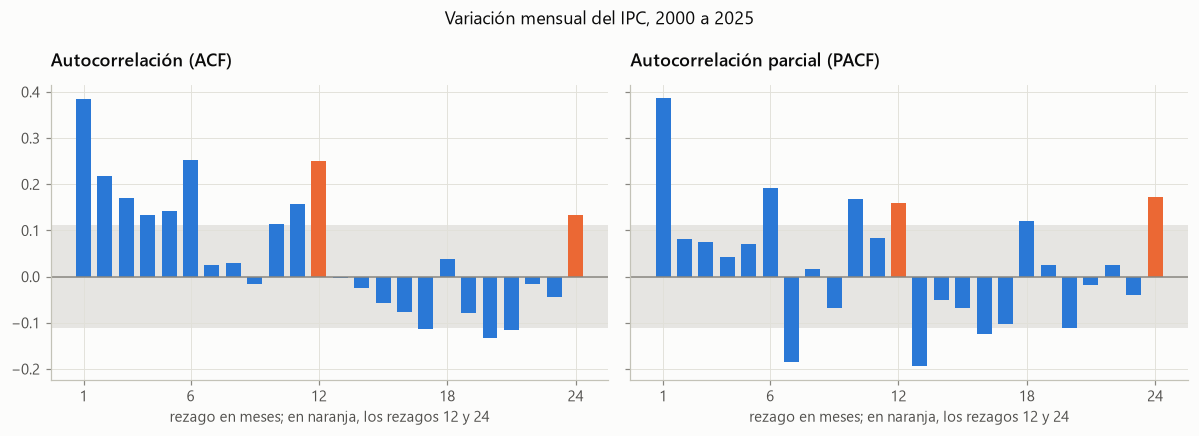

                                          AIC      BIC  Ljung-Box 12, valor p  Ljung-Box 24, valor p
AR(1)                                290.4659 301.6949                 0.0000                 0.0000
AR(1) con AR estacional de rezago 12 269.0139 283.9859                 0.0012                 0.0001

Pronóstico de la variación mensual del IPC para los próximos 12 meses, %:
2026-01-01   0.3800
2026-02-01   0.2800
2026-03-01   0.3400
2026-04-01   0.2700
2026-05-01   0.2800
2026-06-01   0.1100
2026-07-01   0.4700
2026-08-01   0.2200
2026-09-01   0.3300
2026-10-01   0.2200
2026-11-01   0.3100
2026-12-01   0.1700
Freq: MS
Inflación acumulada pronosticada: 3.44%


,parámetro
const,0.3096
ar.L1,0.3968
ar.S.L12,0.2744
sigma2,0.1347


In [32]:
ipc = datos.cargar_indicador(DATOS / "ipc_historico.csv", "ipc", range(1995, 2027)).loc["2000":]
ipc.index = pd.DatetimeIndex(ipc.index, freq="MS")
rezagos = np.arange(1, 25)
acf = sm.tsa.acf(ipc, nlags=24)[1:]
pacf = sm.tsa.pacf(ipc, nlags=24)[1:]
banda = 1.96 / np.sqrt(len(ipc))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, valores, titulo in zip(ejes, (acf, pacf), ("Autocorrelación (ACF)", "Autocorrelación parcial (PACF)")):
    colores = [COLORES[1] if r % 12 == 0 else COLORES[0] for r in rezagos]
    ax.bar(rezagos, valores, color=colores, width=0.7)
    ax.axhspan(-banda, banda, color=NEUTRO, alpha=0.3, linewidth=0, zorder=0)
    ax.axhline(0, color=TINTA_TENUE, linewidth=1)
    ax.set_xticks([1, 6, 12, 18, 24])
    ax.set_xlabel("rezago en meses; en naranja, los rezagos 12 y 24")
    ax.set_title(titulo)
fig.suptitle(f"Variación mensual del IPC, {ipc.index[0]:%Y} a {ipc.index[-1]:%Y}")
fig.tight_layout()
plt.show()

modelos = {"AR(1)": ARIMA(ipc, order=(1, 0, 0)).fit(),
           "AR(1) con AR estacional de rezago 12": ARIMA(ipc, order=(1, 0, 0), seasonal_order=(1, 0, 0, 12)).fit()}
filas = {}
for nombre, m in modelos.items():
    lb = acorr_ljungbox(m.resid, lags=[12, 24])
    filas[nombre] = {"AIC": m.aic, "BIC": m.bic, "Ljung-Box 12, valor p": lb["lb_pvalue"].iloc[0],
                     "Ljung-Box 24, valor p": lb["lb_pvalue"].iloc[1]}
print(pd.DataFrame(filas).T.to_string())
pronostico = modelos["AR(1) con AR estacional de rezago 12"].forecast(12)
print("\nPronóstico de la variación mensual del IPC para los próximos 12 meses, %:")
print(pronostico.round(2).to_string())
print(f"Inflación acumulada pronosticada: {(1 + pronostico / 100).prod() - 1:.2%}")
modelos["AR(1) con AR estacional de rezago 12"].params.to_frame("parámetro")

**Lectura.**

- **La ACF muestra persistencia y estacionalidad:** autocorrelaciones altas en los primeros rezagos y picos en 6, 12 y 24 meses.
- **El término estacional mejora el ajuste.** El AIC baja de 290 a 269 y el BIC de 302 a 284. Pero la prueba de Ljung-Box todavía rechaza que los residuos sean ruido blanco, con un valor p de 0,001 a 12 rezagos: queda estructura sin modelar, como el cambio de régimen de la inflación en 2021 y 2022.
- **El modelo pronostica una inflación acumulada de 3,4% para 2026,** con los meses de mayor inflación en enero y julio. Los datos del IPC del repositorio terminan en diciembre de 2025.

### Ejercicios resueltos

**Ejercicio 10.1. Media, vida media y pronóstico de un AR(1)** *(ejercicio propio)*

Un spread sigue $y_t = 0,2 + 0,9\,y_{t-1} + \varepsilon_t$ y hoy vale 3. Calcula su media de largo plazo, la vida media de un shock y los pronósticos a 1, 5 y 20 períodos.

In [33]:
c, phi, hoy = 0.2, 0.9, 3.0
mu_ = c / (1 - phi)
print(f"Media = 0,2 / 0,1 = {mu_:.1f}; vida media = ln 0,5 / ln 0,9 = {np.log(0.5) / np.log(phi):.2f} períodos")
print("Respuesta: pronósticos a 1, 5 y 20 períodos:", np.round(fa.pronostico_ar1(hoy, mu_, phi, [1, 5, 20]), 3))

Media = 0,2 / 0,1 = 2.0; vida media = ln 0,5 / ln 0,9 = 6.58 períodos
Respuesta: pronósticos a 1, 5 y 20 períodos: [2.9   2.59  2.122]


**Ejercicio 10.2. Estadístico de Ljung-Box** *(ejercicio propio)*

Con 100 observaciones, las tres primeras autocorrelaciones de los residuos son 0,20, 0,10 y 0,05. Calcula Q con 3 rezagos y concluye al 5%.

In [34]:
rhos_ = np.array([0.20, 0.10, 0.05])
n_ = 100
q_ = n_ * (n_ + 2) * np.sum(rhos_**2 / (n_ - np.arange(1, 4)))
print(f"Q = {q_:.2f}; valor crítico chi-cuadrado(3) = {stats.chi2.ppf(0.95, 3):.2f}")
print(f"Respuesta: {'se rechaza' if q_ > stats.chi2.ppf(0.95, 3) else 'no se rechaza'} que los residuos sean ruido blanco.")

Q = 5.42; valor crítico chi-cuadrado(3) = 7.81
Respuesta: no se rechaza que los residuos sean ruido blanco.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

Un proceso AR(1) $y_t = c + \phi y_{t-1} + \varepsilon_t$ es estacionario en covarianza si y solo si:

- **A.** $|\phi| < 1$, de modo que los shocks decaen en el tiempo y la serie revierte a una media constante.
- **B.** $\phi > 1$, un proceso explosivo.
- **C.** $\phi = 1$, una raíz unitaria.
- **D.** $c = 0$ sin importar $\phi$.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** La estacionariedad requiere $|\phi| < 1$: los shocks pasados tienen influencia geométricamente decreciente y el proceso tiene media constante $c/(1-\phi)$ y varianza. Si $\phi = 1$ es un paseo aleatorio (raíz unitaria); si $|\phi| > 1$ explota.

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad avanzada)*

Un proceso AR(1) es y_t = 0,5 + 0,8·y_{t−1} + ε_t. Si hoy y_t = 4, ¿cuál es el pronóstico para dos períodos adelante?

- **A.** 4,00
- **B.** 2,56
- **C.** 3,70
- **D.** 3,46

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** La media de largo plazo es c/(1 − φ) = 0,5/0,2 = 2,5. El pronóstico a h pasos es μ + φ^h·(y_t − μ) = 2,5 + 0,8²·(4 − 2,5) = 2,5 + 0,64·1,5 = 3,46. El valor 3,70 es el pronóstico a un paso.

</details>

### Trampas frecuentes

- La ACF de un AR decae; la de un MA se corta. La PACF hace lo contrario.
- Un AR(1) con φ = 1 no es estacionario: es un paseo aleatorio.
- Si los residuos de un modelo no son ruido blanco, falta estructura por modelar.

## QA-11. Series de tiempo no estacionarias

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Tendencias.** Una tendencia determinística se elimina con una regresión en el tiempo; una estocástica, o raíz unitaria, con diferencias. Confundirlas produce pronósticos equivocados.
- **Raíz unitaria.** El paseo aleatorio $y_t = y_{t-1} + \varepsilon_t$ tiene varianza que crece con t, y los shocks son permanentes. La prueba de Dickey-Fuller aumentada tiene como nula la raíz unitaria, con valores críticos propios, más exigentes que los de la t.
- **Regresión espuria.** Dos series independientes con raíz unitaria producen R² altos y t significativas con frecuencia.
- **Cointegración.** Si dos series I(1) tienen una combinación lineal estacionaria, comparten una tendencia. Engle y Granger: regresar una sobre otra y probar raíz unitaria en los residuos. El modelo de corrección de errores describe cómo se corrigen las desviaciones.
- **Estacionalidad.** Diferencias estacionales o dummies por mes.

### Análisis avanzado: cointegración de las tasas de los bonos del Banco Central

Se usan las tasas mensuales de los bonos en pesos del Banco Central (BCP) a 5 y 10 años desde 2008. Luego se simulan pares de paseos aleatorios independientes para medir cuántas veces una regresión entre ellos parece significativa.

In [35]:
bcp_m = bcp[["5", "10"]].resample("ME").last().dropna()
filas = {}
for nombre, serie in {"BCP 5 años": bcp_m["5"], "BCP 10 años": bcp_m["10"], "cambio del BCP 10": bcp_m["10"].diff().dropna(),
                      "spread 10 - 5": bcp_m["10"] - bcp_m["5"]}.items():
    estadistico, valor_p, *_ = adfuller(serie, autolag="AIC")
    filas[nombre] = {"estadístico ADF": estadistico, "valor p": valor_p}
print(pd.DataFrame(filas).T.to_string())
t_coint, p_coint, _ = coint(bcp_m["10"], bcp_m["5"])
print(f"\nEngle-Granger: estadístico {t_coint:.2f}, valor p {p_coint:.3f}")

spread = bcp_m["10"] - bcp_m["5"]
ar_spread = sm.OLS(spread.iloc[1:].to_numpy(), sm.add_constant(spread.iloc[:-1].to_numpy())).fit()
phi_spread = ar_spread.params[1]
print(f"AR(1) del spread: φ = {phi_spread:.3f}; vida media de una desviación = {np.log(0.5) / np.log(phi_spread):.1f} meses")

rng = np.random.default_rng(11)
t_niveles, t_diferencias = [], []
for _ in range(2_000):
    a, b = np.cumsum(rng.standard_normal((2, 250)), axis=1)
    t_niveles.append(sm.OLS(a, sm.add_constant(b)).fit().tvalues[1])
    t_diferencias.append(sm.OLS(np.diff(a), sm.add_constant(np.diff(b))).fit().tvalues[1])
pd.Series({"regresión en niveles": np.mean(np.abs(t_niveles) > 1.96),
           "regresión en diferencias": np.mean(np.abs(t_diferencias) > 1.96)},
          name="pares independientes con |t| > 1,96").to_frame()

                   estadístico ADF  valor p
BCP 5 años                 -3.3478   0.0129
BCP 10 años                -2.2120   0.2019
cambio del BCP 10         -10.7717   0.0000
spread 10 - 5              -4.7918   0.0001

Engle-Granger: estadístico -3.91, valor p 0.010
AR(1) del spread: φ = 0.896; vida media de una desviación = 6.3 meses


,"pares independientes con |t| > 1,96"
regresión en niveles,0.8410
regresión en diferencias,0.0475


**Lectura.**

- **Las tasas están en el límite de la raíz unitaria.** La tasa a 10 años no la rechaza, con valor p de 0,20; la de 5 años sí la rechaza al 5%, con 0,013. Es un resultado frontera típico: las tasas revierten a la media, pero muy lentamente. El cambio mensual es claramente estacionario.
- **Las dos tasas están cointegradas.** El spread entre 10 y 5 años es estacionario y la prueba de Engle-Granger rechaza la ausencia de cointegración con un valor p de 0,01. Comparten una tendencia, y sus desviaciones se corrigen con una vida media de 6 meses.
- **La regresión espuria es la norma, no la excepción.** Con pares de paseos aleatorios independientes, el 84% de las regresiones en niveles da |t| > 1,96. En diferencias, el 4,8%, lo esperado por azar.

### Ejercicios resueltos

**Ejercicio 11.1. Interpretar una prueba ADF** *(ejercicio propio)*

La prueba ADF sobre el logaritmo de un precio da −1,8 y sobre su primera diferencia da −12,4. El valor crítico al 5% es −2,86. ¿Qué orden de integración tiene la serie y qué hay que modelar?

In [36]:
critico_adf = -2.86
for nombre, valor in [("nivel", -1.8), ("primera diferencia", -12.4)]:
    print(f"{nombre}: {valor} {'<' if valor < critico_adf else '>'} {critico_adf}: {'se rechaza' if valor < critico_adf else 'no se rechaza'} la raíz unitaria")
print("Respuesta: la serie es I(1). Se modelan los retornos logarítmicos, que son estacionarios.")

nivel: -1.8 > -2.86: no se rechaza la raíz unitaria
primera diferencia: -12.4 < -2.86: se rechaza la raíz unitaria
Respuesta: la serie es I(1). Se modelan los retornos logarítmicos, que son estacionarios.


**Ejercicio 11.2. Incertidumbre del pronóstico** *(ejercicio propio)*

Con shocks de desviación 1, compara la desviación del error de pronóstico a 1, 4 y 25 períodos de un paseo aleatorio y de un AR(1) estacionario con φ = 0,8.

In [37]:
horizontes = np.array([1, 4, 25])
paseo = np.sqrt(horizontes)
ar = np.sqrt((1 - 0.8 ** (2 * horizontes)) / (1 - 0.8**2))
print(pd.DataFrame({"paseo aleatorio": paseo, "AR(1), φ = 0,8": ar}, index=pd.Index(horizontes, name="horizonte")).round(3).to_string())
print("Respuesta: en el paseo aleatorio la incertidumbre crece sin límite; en el AR(1) converge a raíz(1 / (1 - φ²)) = 1,667.")

           paseo aleatorio  AR(1), φ = 0,8
horizonte                                 
1                   1.0000          1.0000
4                   2.0000          1.5200
25                  5.0000          1.6670
Respuesta: en el paseo aleatorio la incertidumbre crece sin límite; en el AR(1) converge a raíz(1 / (1 - φ²)) = 1,667.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

Dos series de tiempo financieras, X_t e Y_t, son ambas integradas de orden 1 — I(1). Un analista regresa Y_t sobre X_t y obtiene R² = 0.89 y un t-estadístico altamente significativo. ¿Cuál es la interpretación correcta de estos resultados?

- **A.** Los resultados son inválidos porque solo se puede regresar una serie I(1) sobre una serie I(0).
- **B.** Los resultados pueden ser una regresión espuria a menos que se verifique que los residuos de la regresión son estacionarios (I(0)), lo que indicaría cointegración.
- **C.** El alto R² y t-estadístico confirman automáticamente cointegración entre X e Y.
- **D.** Los resultados son confiables porque el alto R² confirma una relación económica real entre X e Y.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** Cuando se regresa una serie **I(1) sobre otra I(1)**, existe el riesgo de **regresión espuria** (Granger y Newbold, 1974): se obtienen R² elevados y t-estadísticos significativos que parecen indicar una relación, pero en realidad son un artefacto estadístico de las tendencias estocásticas. **Cómo verificar si la relación es real — Test de Cointegración (Engle-Granger):** (1) Estimar la regresión Y_t = α + β·X_t + ε_t; (2) Probar si los residuos ε_t son estacionarios (I(0)) usando el test ADF sobre los residuos. Si ε_t ~ I(0): las series están **cointegradas** — hay una relación de largo plazo genuina. Si ε_t ~ I(1): la regresión es **espuria** — no hay relación real. **Regla práctica para detectar regresión espuria:** R² > DW (estadístico de Durbin-Watson) es señal de alerta de regresión espuria. La opción D es incorrecta — el R² alto por sí solo no valida la relación. La opción C confunde significancia estadística con cointegración.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Un analista trabaja con la serie de precios de un índice bursátil durante 10 años (diario). Antes de estimar un modelo ARMA, realiza las pruebas de Dickey-Fuller Aumentado (ADF) y no puede rechazar la hipótesis nula. ¿Qué implica este resultado y cuál es el tratamiento estadístico correcto?

- **A.** La prueba ADF no es aplicable a series de precios financieros; se debe usar la prueba de Ljung-Box en su lugar.
- **B.** No rechazar H₀ en ADF implica que la serie es estacionaria; el modelo ARMA puede aplicarse directamente a los precios.
- **C.** No rechazar H₀ en ADF implica que la serie tiene una raíz unitaria y es integrada de orden 2 [I(2)]; se deben tomar dos diferencias.
- **D.** No rechazar H₀ en ADF implica que la serie tiene una raíz unitaria y es no estacionaria [I(1)]; el tratamiento correcto es tomar la primera diferencia (retornos logarítmicos) antes de estimar el modelo ARMA.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** **Prueba de Dickey-Fuller Aumentado (ADF):**
- H₀: La serie tiene una raíz unitaria (es no estacionaria)
- H₁: La serie es estacionaria

No rechazar H₀ → la serie de **precios** es probablemente **I(1)** (integrada de orden 1), es decir, no estacionaria.

**¿Por qué son no estacionarios los precios?**
La media y varianza de los precios cambian con el tiempo (tendencia estocástica), violando el supuesto de estacionariedad.

**Tratamiento correcto:**
$$\Delta \ln(P_t) = \ln(P_t) - \ln(P_{t-1}) = r_t$$

Los retornos logarítmicos $r_t$ son típicamente estacionarios [I(0)] y pueden modelarse con ARMA.

**Por qué los distractores son incorrectos:**
- **A**: En ADF, no rechazar H₀ implica NO estacionariedad (lo opuesto).
- **B**: I(2) requeriría no rechazar ADF tanto en la serie original como en su primera diferencia; lo más común en precios es I(1).
- **C**: La prueba ADF es perfectamente válida para series financieras; Ljung-Box prueba autocorrelación, no raíces unitarias.

</details>

### Trampas frecuentes

- En la prueba ADF, no rechazar la nula significa que no se descarta la raíz unitaria.
- Regresar dos series con raíz unitaria da R² altos sin relación real, salvo que estén cointegradas.
- Diferenciar una serie con tendencia determinística introduce un MA no invertible; hay que identificar el tipo de tendencia.

## QA-12. Medición de retornos, volatilidad y correlación

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Retornos.** Simple $R = P_t/P_{t-1} - 1$ y logarítmico $r = \ln(P_t/P_{t-1}) = \ln(1 + R)$. Los logarítmicos se suman en el tiempo; los simples se promedian entre activos de una cartera.
- **Volatilidad.** Con retornos i.i.d., $\sigma_T = \sigma\sqrt{T}$. Con autocorrelación, la regla de la raíz del tiempo falla: la razón de varianzas lo detecta.
- **Volatilidad implícita.** La que iguala el precio de una opción a su valor de mercado. El VIX es la del S&P 500 a 30 días.
- **No normalidad.** Asimetría y curtosis; prueba de Jarque-Bera, $JB = n\left(S^2/6 + (K-3)^2/24\right)$.
- **Correlaciones.** Pearson mide dependencia lineal y es sensible a los extremos. Spearman es la correlación de los rangos y Kendall, la proporción de pares concordantes menos discordantes. Para una cópula gaussiana, $\rho = \sin(\pi\tau/2) = 2\sin(\pi\rho_S/6)$.

### Análisis avanzado: Pearson, Spearman y Kendall entre el IPSA y el dólar

Se calculan las tres correlaciones diarias entre el ETF IPSA y el dólar, y las correlaciones lineales que implican Kendall y Spearman si la dependencia fuera gaussiana. Luego se compara la volatilidad anualizada con datos diarios, semanales y mensuales.

Pearson                   -0.2620
Spearman                  -0.2340
Kendall                   -0.1600
ρ implícita en Kendall    -0.2490
ρ implícita en Spearman   -0.2440


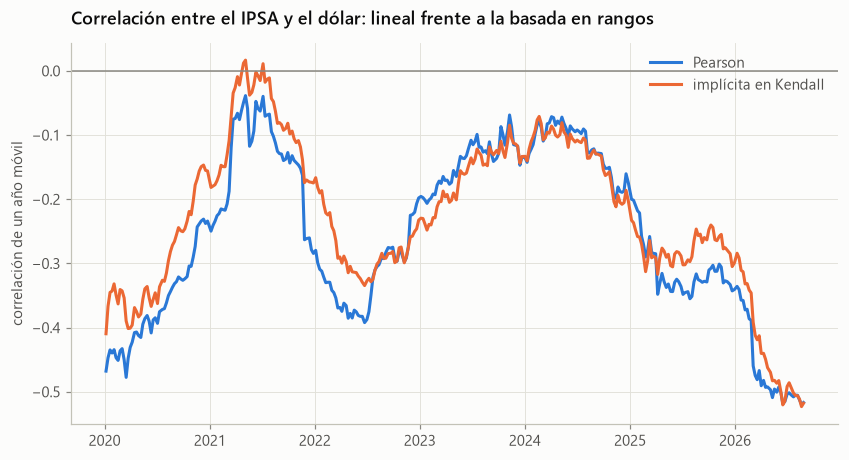


Jarque-Bera diario: IPSA 11,648; dólar 479; ambos con valor p ≈ 0


,IPSA,Dólar
diaria,21.6%,12.8%
semanal,22.9%,13.3%
mensual,18.7%,13.2%


In [38]:
pearson = diario.corr().iloc[0, 1]
spearman = stats.spearmanr(diario["ipsa"], diario["dolar"])[0]
kendall = stats.kendalltau(diario["ipsa"], diario["dolar"])[0]
print(pd.Series({"Pearson": pearson, "Spearman": spearman, "Kendall": kendall,
                 "ρ implícita en Kendall": fa.rho_desde_tau(kendall), "ρ implícita en Spearman": fa.rho_desde_spearman(spearman)}).round(3).to_string())

ventana, paso = 250, 5
fechas, rolling_pearson, rolling_kendall = [], [], []
for fin in range(ventana, len(diario), paso):
    tramo = diario.iloc[fin - ventana:fin]
    fechas.append(tramo.index[-1])
    rolling_pearson.append(tramo.corr().iloc[0, 1])
    rolling_kendall.append(fa.rho_desde_tau(stats.kendalltau(tramo["ipsa"], tramo["dolar"])[0]))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(fechas, rolling_pearson, color=COLORES[0], linewidth=2, label="Pearson")
ax.plot(fechas, rolling_kendall, color=COLORES[1], linewidth=2, label="implícita en Kendall")
ax.axhline(0, color=TINTA_TENUE, linewidth=1)
ax.set_ylabel("correlación de un año móvil")
ax.set_title("Correlación entre el IPSA y el dólar: lineal frente a la basada en rangos")
ax.legend(loc="upper right")
plt.show()

log_niveles = np.log(pd.concat({"IPSA": precios["ETF IPSA"], "Dólar": dolar_alineado}, axis=1, sort=True).loc[precios.index].ffill())
volatilidades = {}
for nombre, regla, periodos in [("diaria", "D", 252), ("semanal", "W-WED", 52), ("mensual", "ME", 12)]:
    r_ = log_niveles.diff().dropna() if regla == "D" else log_niveles.resample(regla).last().diff().dropna()
    volatilidades[nombre] = r_.std() * np.sqrt(periodos)
tabla_vol = pd.DataFrame(volatilidades).T
jb = {c: stats.jarque_bera(log_niveles[c].diff().dropna()) for c in log_niveles}
print(f"\nJarque-Bera diario: IPSA {jb['IPSA'][0]:,.0f}; dólar {jb['Dólar'][0]:,.0f}; ambos con valor p ≈ 0")
tabla_vol.map("{:.1%}".format)

**Lectura.**

- **Las tres medidas cuentan la misma historia.** Pearson da −0,26, Spearman −0,23 y Kendall −0,16, pero las correlaciones lineales implícitas en Kendall y Spearman, −0,25 y −0,24, casi coinciden con Pearson. En el centro de la distribución, la dependencia se parece a la de una cópula gaussiana, aunque en las colas sea mayor, como mostró QA-4.
- **La correlación cambia mucho en el tiempo:** es cercana a cero en 2021 y llega a −0,52 en 2026. Una sola correlación de toda la muestra oculta esa inestabilidad.
- **La raíz del tiempo funciona para el dólar, pero no del todo para el IPSA.** La volatilidad anualizada del dólar casi no depende de la frecuencia, de 12,8% a 13,3%. La del IPSA con datos mensuales, 18,7%, es menor que con datos diarios, 21,6%: parte de los movimientos diarios se revierte. Jarque-Bera rechaza la normalidad en ambos.

### Ejercicios resueltos

**Ejercicio 12.1. Retornos simples y logarítmicos** *(banco de ejercicios de frm-prep)*

Una acción sube de 100 a 110 y al día siguiente baja a 99. Calcula los retornos simples y logarítmicos de cada día y del período completo.

In [39]:
p_ = np.array([100.0, 110.0, 99.0])
simples = p_[1:] / p_[:-1] - 1
logs = np.log(p_[1:] / p_[:-1])
print(f"Simples: {simples.round(4)}; suma {simples.sum():.4f}; total real {p_[-1] / p_[0] - 1:.4f}")
print(f"Respuesta: logarítmicos {logs.round(4)}; su suma {logs.sum():.4f} es exactamente ln(99/100) = {np.log(0.99):.4f}.")

Simples: [ 0.1 -0.1]; suma 0.0000; total real -0.0100
Respuesta: logarítmicos [ 0.0953 -0.1054]; su suma -0.0101 es exactamente ln(99/100) = -0.0101.


**Ejercicio 12.2. De Kendall a Pearson** *(ejercicio propio)*

Dos factores tienen una tau de Kendall de 0,40. Si su dependencia es una cópula gaussiana, ¿qué correlación lineal debe usarse en la simulación? ¿Qué rho de Spearman se esperaría?

In [40]:
rho_ej = fa.rho_desde_tau(0.40)
spearman_ej = 6 / np.pi * np.arcsin(rho_ej / 2)
print(f"ρ = sin(π · 0,40 / 2) = {rho_ej:.4f}")
print(f"Respuesta: la Spearman esperada es (6/π)·arcsin(ρ/2) = {spearman_ej:.4f}.")

ρ = sin(π · 0,40 / 2) = 0.5878
Respuesta: la Spearman esperada es (6/π)·arcsin(ρ/2) = 0.5697.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Una inversión rinde +50% en el año 1 y −50% en el año 2. ¿Cuál es el retorno anual promedio geométrico (compuesto)?

- **A.** −13.4%
- **B.** −25.0%
- **C.** −6.7%
- **D.** 0.0%

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Media geométrica = [(1.50)(0.50)]^(1/2) − 1 = (0.75)^(0.5) − 1 = 0.8660 − 1 = −13.4%. La media aritmética (0%) sobreestima el resultado realizado.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

La correlación de rango (Spearman) es preferible a la correlación de Pearson cuando:

- **A.** Los tamaños de muestra son muy grandes
- **B.** Todos los retornos son positivos
- **C.** Los datos están normalmente distribuidos
- **D.** La relación entre las variables es no lineal o los datos contienen valores atípicos

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** La correlación de rango de Spearman es una medida no paramétrica basada en rangos, no en los valores reales. Captura relaciones monótonas (no necesariamente lineales) y es robusta a valores atípicos, lo que la hace preferible para datos financieros no normales.

</details>

### Trampas frecuentes

- Los retornos logarítmicos se suman en el tiempo; los simples se suman entre activos con sus pesos.
- La raíz del tiempo solo vale con retornos i.i.d.; la reversión a la media o la persistencia la invalidan.
- Pearson puede ser baja con dependencia fuerte no lineal; Spearman y Kendall no cambian ante transformaciones monótonas.

## QA-13. Simulación y bootstrapping

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Monte Carlo.** Se simulan los factores, se revalúa y se promedia. El error estándar cae como $1/\sqrt{N}$: reducirlo a la mitad cuesta cuatro veces más simulaciones.
- **Variables antitéticas.** Se usa cada extracción z y su espejo −z. La varianza del promedio de un par es $\sigma^2(1 + \rho)/2$, que baja si el pago es monótono y ρ < 0.
- **Variables de control.** Se usa una variable correlacionada con valor esperado conocido: $\hat Y_{VC} = \bar Y - b(\bar X - E[X])$, con $b = \text{Cov}(Y, X)/\text{Var}(X)$. La varianza se multiplica por $1 - \rho_{XY}^2$.
- **Bootstrap.** Remuestrea los datos con reemplazo, sin suponer una distribución. Con datos dependientes, como la volatilidad agrupada, se remuestrean bloques.
- **Limitaciones.** La simulación depende del modelo; el bootstrap solo repite lo que está en la muestra y falla con cambios estructurales.

### Análisis avanzado: variables de control y bootstrap por bloques

Se valora una opción asiática aritmética sobre el dólar a un año, con 12 promedios mensuales, strike igual al spot y la volatilidad de los dos últimos años. Se comparan Monte Carlo simple, antitético y con la asiática geométrica como variable de control, cuyo precio exacto se conoce. Luego se construye un intervalo de confianza para el VaR al 99% del IPSA con bootstrap simple y por bloques.

In [41]:
s0 = float(dolar.iloc[-1])
r_clp = 0.045
r_usd = float(datos.cargar_fred("DGS1", DATOS / "fred").iloc[-1]) / 100
vol_usd = float(np.log(dolar).diff().loc[dolar.index[-1] - pd.DateOffset(years=2):].std() * np.sqrt(252))
n_fijaciones, n_rutas = 12, 20_000

def pagos(rutas):
    aritmetico = rutas[:, 1:].mean(axis=1)
    geometrico = np.exp(np.log(rutas[:, 1:]).mean(axis=1))
    return np.maximum(aritmetico - s0, 0), np.maximum(geometrico - s0, 0)

descuento = np.exp(-r_clp)
simple, _ = pagos(fa.simular_gbm(s0, r_clp - r_usd, vol_usd, 1.0, n_fijaciones, n_rutas, semilla=1))
anti, _ = pagos(fa.simular_gbm(s0, r_clp - r_usd, vol_usd, 1.0, n_fijaciones, n_rutas, semilla=1, antiteticas=True))
arit, geom = pagos(fa.simular_gbm(s0, r_clp - r_usd, vol_usd, 1.0, n_fijaciones, n_rutas, semilla=2))
exacto_geom = fa.call_asiatica_geometrica_discreta(s0, s0, r_clp, vol_usd, 1.0, n_fijaciones, q=r_usd)
b_opt = np.cov(arit, geom)[0, 1] / geom.var(ddof=1)
control = descuento * (arit - b_opt * (geom - exacto_geom / descuento))

anti_pares = anti.reshape(2, -1).mean(axis=0)
resultados_mc = {
    "simple": (descuento * simple.mean(), descuento * simple.std(ddof=1) / np.sqrt(n_rutas)),
    "antitético": (descuento * anti_pares.mean(), descuento * anti_pares.std(ddof=1) / np.sqrt(len(anti_pares))),
    "variable de control": (control.mean(), control.std(ddof=1) / np.sqrt(n_rutas)),
}
tabla_mc = pd.DataFrame(resultados_mc, index=["precio", "error estándar"]).T
tabla_mc["simulaciones equivalentes al simple"] = (tabla_mc.loc["simple", "error estándar"] / tabla_mc["error estándar"]) ** 2 * n_rutas
print(f"Spot {s0:,.2f}; volatilidad {vol_usd:.1%}; asiática geométrica exacta {exacto_geom:,.3f};"
      f" correlación entre pagos aritmético y geométrico {np.corrcoef(arit, geom)[0, 1]:.4f}")
print(tabla_mc.round({"precio": 3, "error estándar": 3, "simulaciones equivalentes al simple": 0}).to_string())

def var_99(x_):
    return -np.quantile(x_, 0.01)

intervalos = {}
for nombre, bloque in [("bootstrap simple", 1), ("bootstrap por bloques de 20 días", 20)]:
    remuestreo = fa.bootstrap_bloques(r_ipsa.to_numpy(), var_99, largo_bloque=bloque, repeticiones=2_000, semilla=3)
    intervalos[nombre] = {"VaR 99%": var_99(r_ipsa.to_numpy()), "percentil 2,5%": np.quantile(remuestreo, 0.025),
                          "percentil 97,5%": np.quantile(remuestreo, 0.975), "error estándar": remuestreo.std()}
pd.DataFrame(intervalos).T.map("{:.3%}".format)

Spot 959.39; volatilidad 10.7%; asiática geométrica exacta 23.557; correlación entre pagos aritmético y geométrico 0.9999
                     precio  error estándar  simulaciones equivalentes al simple
simple              23.4380          0.2540                          20,000.0000
antitético          23.7760          0.1940                          34,323.0000
variable de control 23.9920          0.0040                      92,563,391.0000


,VaR 99%,"percentil 2,5%","percentil 97,5%",error estándar
bootstrap simple,3.420%,3.235%,3.946%,0.202%
bootstrap por bloques de 20 días,3.420%,2.901%,5.186%,0.477%


**Lectura.**

- **La variable de control es extraordinaria aquí.** La asiática vale unos 24 pesos por dólar. Con 20.000 trayectorias, el error estándar baja de 0,254 en Monte Carlo simple a 0,194 con variables antitéticas y a 0,004 con la asiática geométrica como control. Como ambos pagos tienen correlación 0,9999, el control equivale a unos 93 millones de simulaciones simples.
- **El bootstrap simple subestima la incertidumbre del VaR.** Su intervalo de 95% para el VaR al 99% va de 3,24% a 3,95%; el bootstrap por bloques de 20 días, de 2,90% a 5,19%, con un error estándar más del doble. Remuestrear días sueltos rompe la agrupación de la volatilidad y hace parecer más preciso de lo que es al VaR.

### Ejercicios resueltos

**Ejercicio 13.1. Tamaño de la simulación** *(banco de ejercicios de frm-prep)*

Una simulación de 5.000 trayectorias da un error estándar de 0,8. ¿Cuántas trayectorias hacen falta para llegar a 0,2? Si una variable de control tiene correlación 0,95 con el pago, ¿cuántas bastarían?

In [42]:
necesarias = 5_000 * (0.8 / 0.2) ** 2
print(f"Sin reducción: 5.000 × (0,8 / 0,2)² = {necesarias:,.0f}")
print(f"Respuesta: con control, la varianza se multiplica por 1 - 0,95² = {1 - 0.95**2:.4f}: bastan unas {necesarias * (1 - 0.95**2):,.0f}.")

Sin reducción: 5.000 × (0,8 / 0,2)² = 80,000
Respuesta: con control, la varianza se multiplica por 1 - 0,95² = 0.0975: bastan unas 7,800.


**Ejercicio 13.2. Método de la transformada inversa** *(ejercicio propio)*

Genera tiempos hasta el incumplimiento con intensidad constante λ = 2% usando uniformes, y verifica que la probabilidad de incumplir antes de 5 años sea $1 - e^{-0,1}$.

In [43]:
rng = np.random.default_rng(13)
u_ = rng.uniform(size=1_000_000)
tiempos = -np.log(1 - u_) / 0.02
print(f"Simulado: {np.mean(tiempos < 5):.4%}; teórico: {1 - np.exp(-0.1):.4%}")
print("Respuesta: si U es uniforme, F⁻¹(U) tiene distribución F. Para la exponencial, F⁻¹(u) = -ln(1 - u)/λ.")

Simulado: 9.5126%; teórico: 9.5163%
Respuesta: si U es uniforme, F⁻¹(U) tiene distribución F. Para la exponencial, F⁻¹(u) = -ln(1 - u)/λ.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Una simulación de Monte Carlo con 10,000 corridas da un error estándar de \$500. Para reducir el error estándar a la mitad, a \$250, el número de corridas necesarias es:

- **A.** 100,000
- **B.** 20,000
- **C.** 5,000
- **D.** 40,000

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** El error estándar de Monte Carlo cae con $1/\sqrt{N}$. Para reducirlo a la mitad, se cuadruplican las corridas: $10{,}000 \times 4 = 40{,}000$.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Las técnicas de reducción de varianza en la simulación de Monte Carlo (p. ej., variables antitéticas, variables de control) están diseñadas para:

- **A.** Garantizar la convergencia al valor verdadero
- **B.** Aumentar el número de trayectorias de simulación
- **C.** Eliminar el sesgo sistemático de la simulación
- **D.** Reducir el error estándar de la estimación de la simulación para un número dado de trayectorias

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Las técnicas de reducción de varianza mejoran la eficiencia de la simulación: logran la misma precisión con menos trayectorias, o más precisión con las mismas trayectorias. Las variables antitéticas usan números aleatorios apareados; las variables de control usan una solución analítica conocida de un problema relacionado.

</details>

### Trampas frecuentes

- Duplicar las simulaciones solo reduce el error estándar en un factor de raíz de 2.
- Las técnicas de reducción de varianza no eliminan el sesgo del modelo.
- El bootstrap simple destruye la dependencia temporal; con volatilidad agrupada subestima la incertidumbre.

## QA-14. Métodos de aprendizaje automático

*Relevancia en el examen: media. Dificultad: avanzada.*

### Idea central

- **Tipos.** Supervisado (con una variable objetivo), no supervisado (buscar estructura) y por refuerzo.
- **Componentes principales.** Transforman variables correlacionadas en componentes no correlacionados ordenados por varianza explicada: los vectores propios de la matriz de covarianza. En la curva de tasas, los tres primeros son nivel, pendiente y curvatura.
- **k-medias.** Asigna cada observación al centroide más cercano y recalcula los centroides hasta converger. Hay que escalar las variables y elegir k, por ejemplo con el codo de la inercia o el coeficiente de silueta.
- **Sobreajuste y regularización.** Ridge (L2) encoge los coeficientes; lasso (L1) lleva algunos a cero y selecciona variables; elastic net combina ambos. La penalización se elige con validación cruzada.
- **Datos.** Entrenamiento, validación y prueba; en series de tiempo, respetando el orden temporal.

### Análisis avanzado: grupos de bancos chilenos con k-medias y componentes principales

Se agrupan los bancos según cinco indicadores de la CMF a junio de 2026: patrimonio efectivo sobre activos ponderados, cartera deteriorada, rentabilidad sobre patrimonio, gastos operacionales sobre activos y morosidad de 90 días o más. Las variables se estandarizan, se resumen en dos componentes principales y se agrupan con k-medias.

16 bancos. Silueta por k: 2: 0.30, 3: 0.28, 4: 0.24, 5: 0.24. Se usa k = 2.
Varianza explicada por los dos componentes: [0.479 0.234]
Cargas de los componentes:
                        CP1     CP2
capital / APR       -0.4700  0.4400
cartera deteriorada  0.5300  0.2600
ROAE                 0.3700 -0.5000
gastos / activos     0.1600  0.6500
mora 90 días         0.5800  0.2600


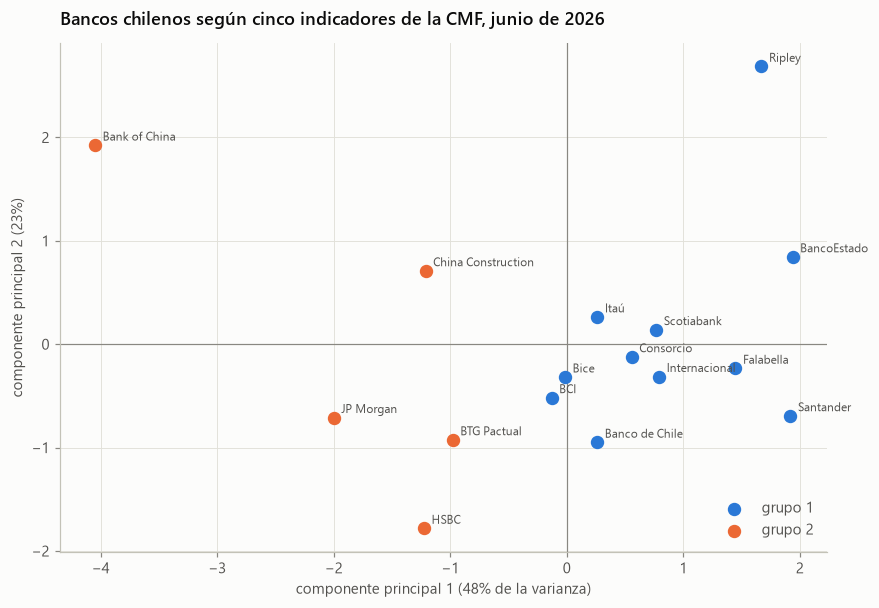

,capital / APR,cartera deteriorada,ROAE,gastos / activos,mora 90 días,grupo
Banco de Chile,17.6400,3.6500,21.4500,2.0900,1.6300,1
Banco de Crédito e Inversiones,15.3200,4.3200,14.8000,1.7600,1.3400,1
Banco Consorcio,20.3300,6.3600,12.1800,0.7900,2.6500,1
Banco del Estado de Chile,17.5200,9.5600,12.4900,2.2500,4.0800,1
Banco Bice,16.2700,4.8200,14.0100,1.9500,1.4700,1
Banco Falabella,17.0000,4.4000,26.3000,4.7400,2.9400,1
Banco Internacional,16.3200,5.3000,17.4300,1.9800,2.6900,1
Banco Itaú Chile,16.8200,6.2500,9.4300,1.7600,2.1500,1
Banco Santander-Chile,16.6100,7.5300,24.4700,1.4100,3.4300,1
Banco Ripley,16.7200,6.1300,13.8700,10.2900,3.4500,1


In [44]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

def indicador_cmf(patron, fecha):
    tabla = pd.read_csv(next((DATOS / "cmf").glob(patron)))
    tabla["fecha"] = pd.to_datetime(tabla["fecha"])
    tabla["codigo"] = tabla["codigo_serie"].str.extract(r"AGIFI_([A-Z0-9]+)_STO")[0]
    tabla = tabla[tabla["fecha"] == fecha]
    return tabla.set_index("codigo")["valor"], tabla.set_index("codigo")["nombre"]

fecha_corte = pd.Timestamp("2026-06-01")
archivos = {"capital / APR": "*PATEFE_APR*", "cartera deteriorada": "*CARDETER*", "ROAE": "*ROAE*",
            "gastos / activos": "*EFICOPER*", "mora 90 días": "*MOR_90*"}
series_cmf = {k: indicador_cmf(p, fecha_corte) for k, p in archivos.items()}
bancos = pd.DataFrame({k: v[0] for k, v in series_cmf.items()}).drop(index="SISTBANC", errors="ignore").dropna()
bancos.index = series_cmf["capital / APR"][1].reindex(bancos.index).str.replace("\xa0", " ").to_numpy()

z_bancos = StandardScaler().fit_transform(bancos)
siluetas = {k: silhouette_score(z_bancos, KMeans(k, n_init=20, random_state=0).fit_predict(z_bancos)) for k in range(2, 6)}
k_mejor = max(siluetas, key=siluetas.get)
grupos = KMeans(k_mejor, n_init=20, random_state=0).fit_predict(z_bancos)
pca = PCA(2).fit(z_bancos)
componentes = pca.transform(z_bancos)
print(f"{len(bancos)} bancos. Silueta por k: " + ", ".join(f"{k}: {v:.2f}" for k, v in siluetas.items()) + f". Se usa k = {k_mejor}.")
print(f"Varianza explicada por los dos componentes: {pca.explained_variance_ratio_.round(3)}")
print("Cargas de los componentes:")
print(pd.DataFrame(pca.components_.T, index=bancos.columns, columns=["CP1", "CP2"]).round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 6))
for g in range(k_mejor):
    ax.scatter(componentes[grupos == g, 0], componentes[grupos == g, 1], s=60, color=COLORES[g], label=f"grupo {g + 1}", zorder=3)
cortos = {"Banco de Crédito e Inversiones": "BCI", "Banco del Estado de Chile": "BancoEstado", "Banco Santander-Chile": "Santander",
          "Jp Morgan Chase Bank. N. A.": "JP Morgan", "HSBC Bank (Chile)": "HSBC", "Banco BTG Pactual Chile": "BTG Pactual",
          "Scotiabank Chile": "Scotiabank", "Banco Itaú Chile": "Itaú", "China Construction Bank": "China Construction"}
for nombre, (c1, c2) in zip(bancos.index, componentes):
    ax.annotate(cortos.get(nombre, nombre.replace("Banco ", "") if nombre != "Banco de Chile" else nombre), (c1, c2), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=TINTA_SECUNDARIA)
ax.axhline(0, color=TINTA_TENUE, linewidth=0.8)
ax.axvline(0, color=TINTA_TENUE, linewidth=0.8)
ax.set_xlabel(f"componente principal 1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
ax.set_ylabel(f"componente principal 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Bancos chilenos según cinco indicadores de la CMF, junio de 2026")
ax.legend(loc="lower right")
fig.savefig(FIGURAS / "bancos_kmedias.png", bbox_inches="tight")
plt.show()
bancos.assign(grupo=grupos + 1).sort_values("grupo").round(2)

**Lectura.**

- **El coeficiente de silueta elige dos grupos.** Uno reúne a los once bancos de personas y empresas locales. El otro, a cinco bancos de nicho y sucursales extranjeras: BTG Pactual, Bank of China, China Construction, HSBC y JP Morgan, con más capital y sin mora relevante.
- **El primer componente, con 48% de la varianza, es un eje de riesgo de crédito:** opone el capital a la cartera deteriorada y la mora. BancoEstado y Santander están en el extremo de mayor deterioro, con 9,6% y 7,5% de cartera deteriorada.
- **El segundo componente, con 23%, refleja los gastos operacionales.** Ripley se separa del resto por gastos de 10,3% de sus activos, propios de un banco de consumo con tarjetas.
- **Con 16 bancos y 5 variables, el análisis es descriptivo.** Los grupos dependen de la estandarización y de casos extremos, como el ratio de capital de 288% de Bank of China.

### Ejercicios resueltos

**Ejercicio 14.1. Ridge en forma cerrada** *(ejercicio propio)*

Con dos regresores muy correlacionados, compara los coeficientes de MCO y de ridge con λ = 10 sobre datos simulados donde el efecto verdadero es 1 para cada regresor.

In [45]:
rng = np.random.default_rng(14)
z1 = rng.standard_normal(100)
x_r = np.column_stack([z1, z1 + 0.05 * rng.standard_normal(100)])
y_r = x_r @ np.array([1.0, 1.0]) + rng.standard_normal(100)
mco = np.linalg.lstsq(x_r, y_r, rcond=None)[0]
ridge = fa.ridge_cerrado(x_r, y_r, 10.0)
print(f"Correlación entre regresores: {np.corrcoef(x_r.T)[0, 1]:.4f}")
print(f"MCO: {mco.round(3)}; ridge: {ridge.round(3)}")
print("Respuesta: MCO reparte el efecto de forma inestable entre los dos regresores; ridge los encoge hacia valores parecidos y estables.")

Correlación entre regresores: 0.9989
MCO: [ 3.222 -1.126]; ridge: [1.014 0.97 ]
Respuesta: MCO reparte el efecto de forma inestable entre los dos regresores; ridge los encoge hacia valores parecidos y estables.


**Ejercicio 14.2. Componentes principales de la curva swap** *(ejercicio propio)*

Con los cambios diarios de las tasas swap cámara a 1, 5 y 10 años, calcula la matriz de covarianza, sus valores y vectores propios y la varianza explicada por cada componente.

In [46]:
cambios_swap = swap[["1", "5", "10"]].diff().dropna() * 100
valores, vectores = np.linalg.eigh(cambios_swap.cov())
orden_pc = np.argsort(valores)[::-1]
valores, vectores = valores[orden_pc], vectores[:, orden_pc]
vectores = vectores * np.sign(vectores[0])
print("Varianza explicada:", (valores / valores.sum()).round(3))
print(pd.DataFrame(vectores, index=["1 año", "5 años", "10 años"], columns=["nivel", "pendiente", "curvatura"]).round(3).to_string())
print("Respuesta: el primer componente mueve los tres plazos en la misma dirección (nivel); el segundo mueve los extremos en direcciones opuestas (pendiente).")

Varianza explicada: [0.845 0.133 0.022]
         nivel  pendiente  curvatura
1 año   0.5600     0.8110     0.1700
5 años  0.6250    -0.2790    -0.7290
10 años 0.5430    -0.5140     0.6630
Respuesta: el primer componente mueve los tres plazos en la misma dirección (nivel); el segundo mueve los extremos en direcciones opuestas (pendiente).


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

En el contexto de modelos de aprendizaje automático aplicados a finanzas, el sobreajuste (overfitting) es un problema crítico. ¿Cuál de las siguientes técnicas es específicamente efectiva para reducir el sobreajuste y seleccionar variables relevantes de forma automática, y cómo lo logra?

- **A.** La regularización Ridge (L2) selecciona automáticamente variables relevantes reduciendo a cero los coeficientes irrelevantes.
- **B.** La validación cruzada (cross-validation) elimina el sobreajuste aumentando el tamaño de la muestra de entrenamiento al máximo posible.
- **C.** El sobreajuste se elimina completamente usando árboles de decisión con profundidad máxima, que capturan todos los patrones en los datos.
- **D.** La regularización Lasso (L1) añade una penalización proporcional al valor absoluto de los coeficientes (λ·Σ|β_j|), lo que tiende a llevar exactamente a cero los coeficientes de variables irrelevantes, logrando selección de variables y reducción del sobreajuste simultáneamente.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** **Sobreajuste:** El modelo ajusta perfectamente los datos de entrenamiento (memoriza el ruido) pero falla en datos nuevos. **Regularización L1 (Lasso):** Minimiza: Σ(y_i − ŷ_i)² + **λ·Σ|β_j|**. La penalización L1 tiene una propiedad geométrica especial: su región de restricción tiene 'esquinas' en los ejes, lo que hace que la solución óptima tienda a estar en una esquina donde varios coeficientes son **exactamente cero**. Efecto: **selección automática de variables** + regularización. **Regularización L2 (Ridge):** Minimiza: Σ(y_i − ŷ_i)² + λ·Σβ²_j. Ridge encoge todos los coeficientes hacia cero, pero **raramente los hace exactamente cero** → no selecciona variables. Útil cuando todas las variables son relevantes. **Elastic Net:** Combina L1 + L2, útil con muchas variables correlacionadas. **Validación cruzada (opción B):** Es un método para estimar el error de generalización y seleccionar hiperparámetros (como λ), pero no elimina el sobreajuste por sí sola. **La opción A describe Lasso (L1), no Ridge (L2)** — esta es una distinción clave en el FRM.

</details>

**Pregunta 2** *(pregunta propia, conceptual, dificultad intermedia)*

En un análisis de componentes principales de los cambios diarios de tasas en ocho plazos, el primer componente explica el 85% de la varianza y tiene cargas casi iguales en todos los plazos. Se interpreta como:

- **A.** un cambio de pendiente.
- **B.** un cambio de nivel de la curva, parecido a un desplazamiento paralelo.
- **C.** un cambio de curvatura.
- **D.** ruido idiosincrático de cada plazo.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** Cargas del mismo signo y tamaño parecido significan que todos los plazos se mueven juntos en la misma dirección: es el factor de nivel. La pendiente tiene cargas de signo opuesto en los extremos, y la curvatura, de un signo en el medio y del otro en los extremos.

</details>

### Trampas frecuentes

- Sin estandarizar, k-medias y los componentes principales quedan dominados por las variables de mayor escala.
- Lasso selecciona variables porque su penalización tiene esquinas; ridge nunca lleva coeficientes exactamente a cero.
- Un modelo con error de entrenamiento casi nulo suele estar sobreajustado; lo que importa es el error fuera de la muestra.

## QA-15. Aprendizaje automático y predicción

*Relevancia en el examen: media. Dificultad: avanzada.*

### Idea central

- **Regresión logística.** $P(y = 1|x) = 1/(1 + e^{-x'\beta})$, estimada por máxima verosimilitud. Sus coeficientes son efectos sobre el logaritmo de las chances.
- **Árboles de decisión.** Dividen los datos para reducir la impureza, medida con Gini, $1 - \sum p_k^2$, o con entropía. Son interpretables pero inestables.
- **Conjuntos.** Bagging y bosques aleatorios promedian árboles entrenados en remuestreos y con subconjuntos de variables; boosting agrega árboles pequeños que corrigen los errores de los anteriores.
- **Redes neuronales.** Capas de combinaciones lineales con funciones de activación no lineales; muy flexibles y propensas al sobreajuste.
- **Evaluación.** Matriz de confusión, precisión, sensibilidad, especificidad, F1, curva ROC y AUC, y calibración de las probabilidades. El umbral de decisión depende del costo de cada error: $p^* = C_{FP}/(C_{FP} + C_{FN})$.

### Análisis avanzado: modelos de incumplimiento, curvas ROC y umbral de costo mínimo

Se simulan 6.000 créditos de consumo con cinco variables. La probabilidad de incumplir sube de forma no lineal cuando la carga financiera supera 40% del ingreso, e interactúa con los atrasos previos. La constante se calibra para una tasa de incumplimiento de 8%. Los datos son sintéticos; la estructura imita la de un modelo de originación.

Tasa de incumplimiento: 7.5%
                        AUC validación cruzada  AUC prueba  Brier prueba
regresión logística                     0.7927      0.7719        0.0596
árbol de decisión                       0.7775      0.7430        0.0596
bosque aleatorio                        0.7963      0.7658        0.0584
boosting                                0.7863      0.7564        0.0590
probabilidad verdadera                     NaN      0.7963        0.0571


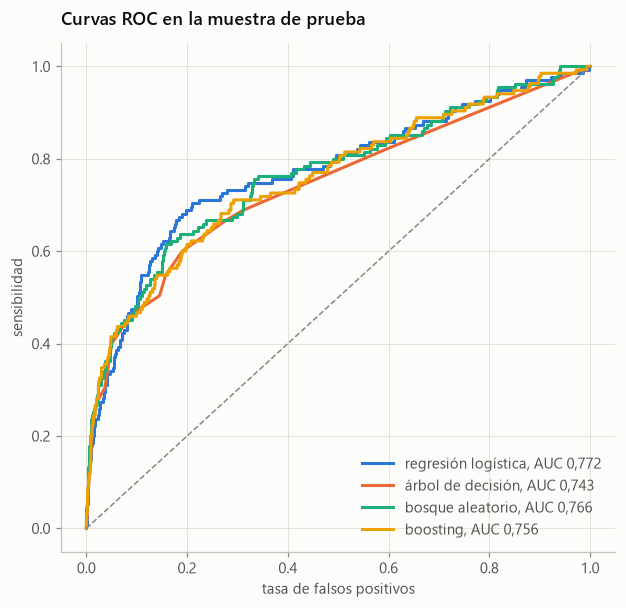


Mejor modelo: regresión logística. Costo de aprobar a quien incumple = 9 veces el de rechazar a un buen cliente.


,rechazados,incumplimientos detectados,incumplimientos aprobados,buenos rechazados,costo por solicitud
umbral de rechazo,,,,,
50%,10.0000,7.0000,128.0000,3.0000,0.6417
20%,172.0000,55.0000,80.0000,117.0000,0.4650
10%,406.0000,91.0000,44.0000,315.0000,0.3950
5%,758.0000,102.0000,33.0000,656.0000,0.5294


In [47]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

rng = np.random.default_rng(15)
n_cred = 6_000
creditos = pd.DataFrame({
    "ingreso": rng.lognormal(np.log(900), 0.5, n_cred),
    "carga financiera": np.clip(rng.beta(2, 5, n_cred) * 1.2, 0, 1.2),
    "antigüedad laboral": rng.exponential(60, n_cred),
    "atrasos previos": rng.poisson(0.4, n_cred),
    "edad": rng.integers(21, 70, n_cred),
})
indice_riesgo = (-0.6 * np.log(creditos["ingreso"] / 900) + 6.0 * np.maximum(creditos["carga financiera"] - 0.40, 0)
                 + 0.5 * creditos["atrasos previos"] + 1.5 * (creditos["atrasos previos"] > 0) * (creditos["carga financiera"] > 0.5)
                 - 0.006 * creditos["antigüedad laboral"] + 0.6 * (creditos["edad"] < 25))
constante = optimize.brentq(lambda c: (1 / (1 + np.exp(-(c + indice_riesgo)))).mean() - 0.08, -10, 5)
prob_real = 1 / (1 + np.exp(-(constante + indice_riesgo)))
incumple = rng.binomial(1, prob_real)
x_tr, x_te, y_tr, y_te = train_test_split(creditos, incumple, test_size=0.3, stratify=incumple, random_state=0)

modelos_ml = {
    "regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1_000)),
    "árbol de decisión": DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=0),
    "bosque aleatorio": RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=20, random_state=0, n_jobs=-1),
    "boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0),
}
filas, probabilidades = {}, {}
for nombre, modelo in modelos_ml.items():
    cv = cross_val_score(modelo, x_tr, y_tr, cv=5, scoring="roc_auc")
    modelo.fit(x_tr, y_tr)
    probabilidades[nombre] = modelo.predict_proba(x_te)[:, 1]
    filas[nombre] = {"AUC validación cruzada": cv.mean(), "AUC prueba": roc_auc_score(y_te, probabilidades[nombre]),
                     "Brier prueba": brier_score_loss(y_te, probabilidades[nombre])}
filas["probabilidad verdadera"] = {"AUC validación cruzada": np.nan, "AUC prueba": roc_auc_score(y_te, prob_real[x_te.index]),
                                   "Brier prueba": brier_score_loss(y_te, prob_real[x_te.index])}
print(f"Tasa de incumplimiento: {incumple.mean():.1%}")
print(pd.DataFrame(filas).T.round(4).to_string())

fig, ax = plt.subplots(figsize=(6.5, 6))
for color, (nombre, p) in zip(COLORES, probabilidades.items()):
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{nombre}, AUC {roc_auc_score(y_te, p):.3f}".replace(".", ","))
ax.plot([0, 1], [0, 1], color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.set_xlabel("tasa de falsos positivos")
ax.set_ylabel("sensibilidad")
ax.set_title("Curvas ROC en la muestra de prueba")
ax.legend(loc="lower right")
plt.show()

mejor = max(probabilidades, key=lambda n: roc_auc_score(y_te, probabilidades[n]))
costo_fp, costo_fn = 1.0, 9.0
umbrales_costo = {}
for umbral in (0.50, 0.20, costo_fp / (costo_fp + costo_fn), 0.05):
    pred = probabilidades[mejor] >= umbral
    vp = int(((pred == 1) & (y_te == 1)).sum()); fp = int(((pred == 1) & (y_te == 0)).sum())
    fn = int(((pred == 0) & (y_te == 1)).sum()); vn = int(((pred == 0) & (y_te == 0)).sum())
    umbrales_costo[f"{umbral:.0%}"] = {"rechazados": vp + fp, "incumplimientos detectados": vp, "incumplimientos aprobados": fn,
                                       "buenos rechazados": fp, "costo por solicitud": (costo_fp * fp + costo_fn * fn) / len(y_te)}
print(f"\nMejor modelo: {mejor}. Costo de aprobar a quien incumple = 9 veces el de rechazar a un buen cliente.")
pd.DataFrame(umbrales_costo).T.rename_axis("umbral de rechazo")

**Lectura.**

- **Todos los modelos ordenan bien a los deudores.** Su AUC de prueba va de 0,74 a 0,77, cerca del 0,80 de la probabilidad verdadera, que es el máximo alcanzable porque el incumplimiento tiene un componente aleatorio.
- **La regresión logística gana pese a la no linealidad.** Con unos 450 incumplimientos en total, los modelos flexibles no tienen datos suficientes para superar a un modelo simple. El árbol de decisión, el más inestable, queda último.
- **El umbral importa más que el modelo.** Con un umbral de 50% casi no se rechaza a nadie y el costo por solicitud es 0,64. Con el umbral de 10% que dicta la razón de costos, baja a 0,40, 38% menos. Un umbral de 5% rechaza demasiado y el costo vuelve a subir.

### Ejercicios resueltos

**Ejercicio 15.1. Métricas de la matriz de confusión** *(ejercicio propio)*

Un modelo de fraude revisa 1.000 transacciones: 30 verdaderos positivos, 20 falsos positivos, 10 falsos negativos y 940 verdaderos negativos. Calcula sus métricas y explica por qué la exactitud engaña.

In [48]:
m_ = fa.metricas_confusion(vp=30, fp=20, fn=10, vn=940)
print({k: round(v, 4) for k, v in m_.items()})
print(f"Respuesta: la exactitud es {m_['exactitud']:.1%}, pero un modelo que nunca marca fraude tendría {960 / 1000:.1%}."
      " Con clases desbalanceadas importan la precisión, la sensibilidad y el AUC.")

{'exactitud': 0.97, 'precision': 0.6, 'sensibilidad': 0.75, 'especificidad': 0.9792, 'f1': 0.6667}
Respuesta: la exactitud es 97.0%, pero un modelo que nunca marca fraude tendría 96.0%. Con clases desbalanceadas importan la precisión, la sensibilidad y el AUC.


**Ejercicio 15.2. Impureza de Gini de una división** *(ejercicio propio)*

Un nodo tiene 100 créditos, con 20 incumplimientos. Una división deja 40 créditos con 15 incumplimientos a la izquierda y 60 con 5 a la derecha. ¿Cuánto reduce la impureza de Gini?

In [49]:
def gini(positivos, total):
    p_ = positivos / total
    return 1 - p_**2 - (1 - p_) ** 2

padre = gini(20, 100)
hijos = 0.4 * gini(15, 40) + 0.6 * gini(5, 60)
print(f"Gini del padre {padre:.4f}; izquierda {gini(15, 40):.4f}; derecha {gini(5, 60):.4f}; promedio ponderado {hijos:.4f}")
print(f"Respuesta: la división reduce la impureza en {padre - hijos:.4f}. El árbol elige la división con mayor reducción.")

Gini del padre 0.3200; izquierda 0.4688; derecha 0.1528; promedio ponderado 0.2792
Respuesta: la división reduce la impureza en 0.0408. El árbol elige la división con mayor reducción.


### Preguntas de práctica

**Pregunta 1** *(pregunta propia, cálculo, dificultad intermedia)*

Un modelo de alerta temprana clasifica 200 créditos. Tiene 40 verdaderos positivos, 10 falsos positivos, 20 falsos negativos y 130 verdaderos negativos, donde positivo significa incumplimiento. ¿Cuál es su sensibilidad (recall)?

- **A.** 85,0%
- **B.** 80,0%
- **C.** 66,7%
- **D.** 92,9%

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Sensibilidad = VP / (VP + FN) = 40 / 60 = 66,7%: el modelo detecta dos de cada tres incumplimientos. El 80% es la precisión, VP / (VP + FP); el 85% es la exactitud, y el 92,9% la especificidad, VN / (VN + FP).

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad avanzada)*

Aprobar un crédito que luego incumple cuesta 9 veces más que rechazar a un buen cliente. Si el modelo entrega probabilidades de incumplimiento bien calibradas, ¿sobre qué probabilidad conviene rechazar la solicitud?

- **A.** 10%
- **B.** 50%
- **C.** 11,1%
- **D.** 90%

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Se rechaza cuando el costo esperado de aprobar supera el de rechazar: p·C_FN > (1 − p)·C_FP. Despejando, p* = C_FP / (C_FP + C_FN) = 1 / (1 + 9) = 10%. El umbral de 50% solo es óptimo cuando ambos errores cuestan lo mismo.

</details>

### Trampas frecuentes

- La exactitud engaña con clases desbalanceadas: un modelo que nunca predice incumplimiento puede tener 92%.
- El AUC no depende del umbral; la matriz de confusión sí.
- Un buen ordenamiento (AUC alto) no garantiza probabilidades calibradas.
- El umbral de 50% solo es óptimo si ambos errores cuestan lo mismo.

## Resumen del libro

- **Las colas mandan.** La mezcla de regímenes y la t de Student explican las colas del IPSA mejor que la normal, y la cópula t explica mejor que la gaussiana cuándo llegan juntas las caídas.
- **La incertidumbre de las estimaciones es enorme.** La curtosis, el Sharpe y los pesos óptimos se estiman con mucho error, y probar muchas hipótesis produce descubrimientos falsos.
- **La regresión exige diagnóstico:** variables omitidas, heterocedasticidad, observaciones influyentes y raíces unitarias cambian las conclusiones.
- **La simulación y el aprendizaje automático** son herramientas poderosas cuando se controla su error: variables de control, bootstrap por bloques, validación cruzada y umbrales basados en costos.